# GELAR RASA — Tahap 1: EDA, Preprocessing, Kemiripan, dan Clustering

**Tujuan:** memahami 1.920 train tanpa target kategori resmi dan 480 test, menyusun preprocessing yang dapat dilacak, memeriksa kemiripan, serta menghasilkan kelompok anonim untuk ditelaah tim.

**Batas hasil:** cluster tidak sama dengan kelas. Tidak ada Accuracy kategori atau submission pada tahap ini. Nama kategori diberikan tim pada tingkat cluster setelah hasil diperiksa. Tidak ada pemanggilan layanan inference eksternal.

**Cara menjalankan:** jalankan dari atas ke bawah dalam proyek GELAR-RASA; data sesuai struktur `data/Dataset DSC GelarRasa 2026/{train,test}` dan `data/SampleSubmission_DSC.csv`. Ubah `PROJECT_ROOT` bila perlu. `GELAR_DATA_ROOT` dan `GELAR_WORK_ROOT` dapat memisahkan input/output. Eksekusi pertama memerlukan bobot ResNet50 ImageNet1K V2 yang tersedia di cache PyTorch atau internet untuk unduhan resmi. Tidak ada pemasangan paket otomatis.

**Urutan:** integritas → metadata/transform → hash → distribusi → fitur → cluster → retrieval → evaluasi diagnostik → grafik/galeri → pemeriksaan akhir. Semua tahap komputasi dijalankan ulang saat Run All; file hasil bukan pengganti eksekusi.

In [1]:
from pathlib import Path
import os
from IPython.display import display, Markdown, Image as DisplayImage
PROJECT_ROOT = Path(os.environ['GELAR_PROJECT_ROOT']).resolve() if 'GELAR_PROJECT_ROOT' in os.environ else next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/data_contract.json').exists())
print('Project:', PROJECT_ROOT)

Project: D:\lomba\NSC UB\GELAR-RASA


## 1. Metode yang dapat direproduksi

Kode fungsi lengkap disertakan agar notebook tidak bergantung pada berkas skrip yang tersembunyi. Seed, transform, lingkungan, dan bobot dicatat. Membaca fungsi saja belum berarti hasil telah dihitung; sel berikutnya mengeksekusi tiap tahap.

Inspirasi kualitas penulisan berasal dari umpan balik INFEST: hubungan temuan data dengan preprocessing, visualisasi disertai interpretasi, dan hasil eksekusi tersimpan. Aturan dan metrik INFEST tidak dipindahkan ke kompetisi ini.

In [2]:
"""GELAR RASA stage 1: reproducible technical EDA and unsupervised grouping.

No language-model service, semantic class assignment, or label archive is used.
Frozen CNN features are exploratory; this is not a trained final classifier.
"""
from __future__ import annotations

import hashlib
import importlib.metadata
import itertools
import json
import os
import platform
import shutil
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import imagehash
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from scipy.spatial.distance import jensenshannon
from scipy.stats import ks_2samp, wasserstein_distance
from skimage.feature import hog

VERSION = 'stage1_v1'
SEED = 20261105
CONFIG = dict(version=VERSION, seed=SEED, image_size=224,
              alpha_background=[255, 255, 255], pad_fill=[124, 116, 104],
              cnn='resnet50', weights='IMAGENET1K_V2',
              fit_population='unique_train_pixel_hash_only', primary_k=8,
              phash_bits=64, candidate_phash_threshold=6,
              candidate_group_threshold=4, cluster_seeds=[11, 29, 47, 83, 131])
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff', '.gif'}


def dump_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding='utf-8')


def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()


def frame_write(df, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False, encoding='utf-8')


def log(ctx, message):
    line = time.strftime('%Y-%m-%d %H:%M:%S') + ' ' + message
    print(line, flush=True)
    with (ctx['report'] / 'run.log').open('a', encoding='utf-8') as f:
        f.write(line + '\n')


def setup(project_root=None):
    if project_root is None:
        candidates = [Path.cwd(), *Path.cwd().parents]
        project_root = next((p for p in candidates if (p / 'configs/data_contract.json').exists()), None)
    if project_root is None:
        raise RuntimeError('Set PROJECT_ROOT to the GELAR-RASA project directory.')
    root = Path(project_root).resolve()
    work = Path(os.environ.get('GELAR_WORK_ROOT', str(root))).resolve()
    data = Path(os.environ.get('GELAR_DATA_ROOT', str(root / 'data'))).resolve()
    ctx = dict(root=root, work=work, data=data,
               report=work / 'reports/eda/stage1_20261105',
               processed=work / 'data/processed' / VERSION,
               manifests=work / 'output/manifests' / VERSION,
               groups=work / 'output/groups' / VERSION,
               embeddings=work / 'output/embeddings' / VERSION)
    for k in ['report', 'processed', 'manifests', 'groups', 'embeddings']:
        ctx[k].mkdir(parents=True, exist_ok=True)
    (ctx['report'] / 'figures').mkdir(exist_ok=True)
    (ctx['report'] / 'galleries').mkdir(exist_ok=True)
    (ctx['processed'] / 'cluster_views').mkdir(exist_ok=True)
    config_file = ctx['processed'] / 'config.json'
    if config_file.exists() and json.loads(config_file.read_text()) != CONFIG:
        raise RuntimeError('Existing version has a different config. Use a new version, do not overwrite.')
    dump_json(config_file, CONFIG)
    packages = ['numpy', 'pandas', 'Pillow', 'scipy', 'scikit-learn', 'scikit-image',
                'opencv-python', 'ImageHash', 'matplotlib', 'torch', 'torchvision', 'nbformat']
    versions = {}
    for p in packages:
        try:
            versions[p] = importlib.metadata.version(p)
        except importlib.metadata.PackageNotFoundError:
            versions[p] = 'not installed under this distribution name'
    dump_json(ctx['report'] / 'environment.json', dict(python=platform.python_version(),
              platform=platform.platform(), packages=versions, config=CONFIG,
              free_disk_gib=shutil.disk_usage(work).free / 2**30))
    (ctx['report'] / 'requirements_observed.txt').write_text('\n'.join(
        f'{k}=={v}' for k, v in versions.items() if 'not installed' not in v) + '\n', encoding='utf-8')
    log(ctx, 'Setup complete. No category targets are loaded.')
    return ctx


def canonical_rgb(path):
    with Image.open(path) as source:
        source.load()
        image = ImageOps.exif_transpose(source)
        has_alpha = 'A' in image.getbands() or 'transparency' in image.info
        if has_alpha:
            rgba = image.convert('RGBA')
            bg = Image.new('RGBA', rgba.size, tuple(CONFIG['alpha_background']) + (255,))
            image = Image.alpha_composite(bg, rgba).convert('RGB')
        else:
            image = image.convert('RGB')
        return image.copy()


def letterbox(image, size=224):
    scale = size / max(image.size)
    dims = tuple(max(1, min(size, round(v * scale))) for v in image.size)
    fitted = image.resize(dims, Image.Resampling.LANCZOS)
    canvas = Image.new('RGB', (size, size), tuple(CONFIG['pad_fill']))
    left, top = (size - dims[0]) // 2, (size - dims[1]) // 2
    canvas.paste(fitted, (left, top))
    return canvas, dict(resized_width=dims[0], resized_height=dims[1],
                        pad_left=left, pad_top=top, scale=scale,
                        padding_fraction=1 - dims[0] * dims[1] / size**2)


def inventory(ctx):
    contract = json.loads((ctx['root'] / 'configs/data_contract.json').read_text(encoding='utf-8'))
    dataset = ctx['data'] / 'Dataset DSC GelarRasa 2026'
    sample = pd.read_csv(ctx['data'] / 'SampleSubmission_DSC.csv', dtype=str)
    if list(sample.columns) != contract['submission_columns'] or sample.image_id.duplicated().any():
        raise AssertionError('Sample schema or duplicate ID failure')
    rows, extra = [], []
    for split in ['train', 'test']:
        folder = dataset / split
        files = sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in EXTENSIONS)
        other = [p.name for p in folder.iterdir() if p.is_file() and p.suffix.lower() not in EXTENSIONS]
        extra.extend(dict(split=split, filename=name) for name in other)
        assert len(files) == contract[f'{split}_count'], (split, len(files))
        assert len({p.stem for p in files}) == len(files), 'Duplicate source ID'
        if split == 'test':
            by_id = {p.stem: p for p in files}
            assert set(by_id) == set(sample.image_id), 'Test IDs differ from sample'
            files = [by_id[i] for i in sample.image_id]
        for p in files:
            assert p.stem.isdigit() and len(p.stem) == contract[f'{split}_id_width']
            rows.append(dict(key=split + ':' + p.stem, split=split, image_id=p.stem,
                             filename=p.name, source_path=str(p.relative_to(ctx['data'])),
                             byte_size=p.stat().st_size, source_sha256=sha(p)))
    df = pd.DataFrame(rows)
    digest = hashlib.sha256(df[['key', 'source_sha256']].to_csv(index=False).encode()).hexdigest()
    prior = ctx['manifests'] / 'input_fingerprint.json'
    if prior.exists():
        assert json.loads(prior.read_text())['digest'] == digest, 'Sources changed; increment version'
    dump_json(prior, dict(digest=digest, images=len(df), ignored_root_files=extra,
                         train_scan='direct children only; subdirectories excluded',
                         sample_target_values_used=False))
    frame_write(df, ctx['manifests'] / 'sources.csv')
    log(ctx, f'Inventory: {len(df)} sources, unique IDs, test order follows sample.')
    return df


def pixel_digest(image):
    return hashlib.sha256(f'RGB:{image.width}:{image.height}:'.encode() + image.tobytes()).hexdigest()


def profile_one(task):
    ctx, row = task
    row = dict(row)
    path = ctx['data'] / row['source_path']
    try:
        with Image.open(path) as src:
            src.load()
            row.update(source_format=src.format, source_mode=src.mode,
                       original_width=src.width, original_height=src.height,
                       exif_orientation=int(src.getexif().get(274, 1)),
                       has_alpha=('A' in src.getbands() or 'transparency' in src.info),
                       icc_profile_present=bool(src.info.get('icc_profile')),
                       n_frames=getattr(src, 'n_frames', 1))
        image = canonical_rgb(path)
        arr = np.asarray(image)
        thumb = ImageOps.contain(image, (256, 256), Image.Resampling.LANCZOS)
        a = np.asarray(thumb)
        gray = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
        hsv = cv2.cvtColor(a, cv2.COLOR_RGB2HSV)
        hist = np.bincount(gray.ravel(), minlength=256) / gray.size
        probs = hist[hist > 0]
        row.update(width=image.width, height=image.height, min_side=min(image.size),
                   aspect_ratio=image.width / image.height, megapixels=image.width * image.height / 1e6,
                   pixel_sha256=pixel_digest(image), brightness=float(gray.mean() / 255),
                   contrast=float(gray.std() / 255), saturation=float(hsv[:, :, 1].mean() / 255),
                   grayscale_entropy_bits=float(-(probs * np.log2(probs)).sum()),
                   dark_fraction=float((gray <= 8).mean()), bright_fraction=float((gray >= 247).mean()),
                   laplacian_variance_256=float(cv2.Laplacian(gray, cv2.CV_64F).var()),
                   edge_fraction=float((cv2.Canny(gray, 100, 200) > 0).mean()),
                   effective_grayscale=bool(np.max(np.ptp(a.astype(np.int16), axis=2)) <= 2),
                   bytes_per_pixel=row['byte_size'] / (image.width * image.height),
                   decode_status='ok', decode_error='')
        for i, name in enumerate(['r', 'g', 'b']):
            row[f'mean_{name}'] = float(a[:, :, i].mean() / 255)
            row[f'std_{name}'] = float(a[:, :, i].std() / 255)
        row['phash'] = str(imagehash.phash(image, hash_size=8))
        row['phash_hflip'] = str(imagehash.phash(ImageOps.mirror(image), hash_size=8))
        row['phash_vflip'] = str(imagehash.phash(ImageOps.flip(image), hash_size=8))
        row['dhash'] = str(imagehash.dhash(image, hash_size=8))
        row['whash'] = str(imagehash.whash(image, hash_size=8))
        output = ctx['processed'] / 'rgb_native' / row['split'] / (row['image_id'] + '.png')
        output.parent.mkdir(parents=True, exist_ok=True)
        image.save(output, format='PNG', compress_level=3)
        with Image.open(output) as check:
            check.load()
            assert check.mode == 'RGB' and np.array_equal(arr, np.asarray(check))
        boxed, geometry = letterbox(image)
        preview = ctx['processed'] / 'letterbox224' / row['split'] / (row['image_id'] + '.png')
        preview.parent.mkdir(parents=True, exist_ok=True)
        boxed.save(preview, format='PNG', compress_level=3)
        row.update(geometry)
        row.update(processed_path=str(output.relative_to(ctx['work'])),
                   processed_sha256=sha(output), preview_path=str(preview.relative_to(ctx['work'])),
                   preview_sha256=sha(preview), rgb_roundtrip_exact=True)
        small = np.asarray(image.resize((128, 128), Image.Resampling.LANCZOS))
        hsv_small = cv2.cvtColor(small, cv2.COLOR_RGB2HSV)
        color = np.concatenate([np.histogram(hsv_small[:, :, i], bins=b, range=(0, high))[0]
                                for i, b, high in [(0, 16, 180), (1, 8, 256), (2, 8, 256)]]).astype('float32')
        color /= 128 * 128
        shape = hog(cv2.cvtColor(small, cv2.COLOR_RGB2GRAY), orientations=9,
                    pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm='L2-Hys').astype('float32')
        return row, color, shape
    except Exception as exc:
        row.update(decode_status='error', decode_error=f'{type(exc).__name__}: {exc}')
        return row, None, None


def profile_and_preprocess(ctx, sources):
    cv2.setNumThreads(1)
    rows, color, shape = [], [], []
    tasks = [(ctx, row) for row in sources.to_dict('records')]
    with ThreadPoolExecutor(max_workers=6) as pool:
        for i, (row, c, h) in enumerate(pool.map(profile_one, tasks)):
            rows.append(row)
            color.append(c)
            shape.append(h)
            if (i + 1) % 200 == 0:
                log(ctx, f'Decode/normalize/hash: {i + 1}/{len(tasks)}')
    df = pd.DataFrame(rows)
    frame_write(df, ctx['manifests'] / 'image_profile.csv')
    errors = df[df.decode_status != 'ok']
    frame_write(errors, ctx['report'] / 'decode_errors.csv')
    if len(errors):
        raise RuntimeError(f'{len(errors)} images failed. See decode_errors.csv; no silent exclusion.')
    np.savez_compressed(ctx['embeddings'] / 'classical_features.npz',
                        keys=df.key.to_numpy(dtype=str), color=np.stack(color), hog=np.stack(shape))
    frame_write(df[['key', 'split', 'image_id', 'source_path', 'source_sha256', 'pixel_sha256',
                    'processed_path', 'processed_sha256', 'preview_path', 'preview_sha256',
                    'width', 'height', 'scale', 'pad_left', 'pad_top', 'padding_fraction',
                    'rgb_roundtrip_exact']], ctx['processed'] / 'preprocessing_manifest.csv')
    log(ctx, 'All images decoded and canonical RGB PNG pixels verified. No files excluded.')
    return df


class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))

    def find(self, i):
        while self.parent[i] != i:
            self.parent[i] = self.parent[self.parent[i]]
            i = self.parent[i]
        return i

    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a != b:
            self.parent[max(a, b)] = min(a, b)


def hash_array(values):
    return np.array([list(bytes.fromhex(v)) for v in values], dtype=np.uint8)


def hamming_matrix(left, right):
    lookup = np.array([i.bit_count() for i in range(256)], dtype=np.uint8)
    out = np.empty((len(left), len(right)), dtype=np.uint8)
    for start in range(0, len(left), 128):
        out[start:start + 128] = lookup[np.bitwise_xor(left[start:start + 128, None, :], right[None, :, :])].sum(2)
    return out


def pair_table(df, pairs, kind, distances=None):
    records = []
    for i, j in pairs:
        r = dict(key_a=df.iloc[i].key, key_b=df.iloc[j].key,
                 split_pair='-'.join(sorted([df.iloc[i].split, df.iloc[j].split])), kind=kind)
        if distances is not None:
            r['hamming'] = int(distances[i, j])
        records.append(r)
    cols = ['key_a', 'key_b', 'split_pair', 'kind'] + (['hamming'] if distances is not None else [])
    return pd.DataFrame(records, columns=cols)


def audit_duplicates(ctx, df):
    n = len(df)
    exact_uf = UnionFind(n)
    for col in ['source_sha256', 'pixel_sha256']:
        pairs = []
        for indices in df.groupby(col, sort=False).indices.values():
            for i, j in itertools.combinations(indices, 2):
                pairs.append((i, j))
                exact_uf.union(int(i), int(j))
        frame_write(pair_table(df, pairs, col), ctx['groups'] / f'{col}_pairs.csv')
    ph = hash_array(df.phash)
    direct = hamming_matrix(ph, ph)
    flip = np.minimum(hamming_matrix(ph, hash_array(df.phash_hflip)),
                      hamming_matrix(ph, hash_array(df.phash_vflip)))
    minimum = np.minimum(direct, flip)
    # Resampling/threshold quantization can make transformed-hash comparison
    # direction-dependent. An undirected candidate edge uses either orientation.
    minimum = np.minimum(minimum, minimum.T)
    assert np.array_equal(minimum, minimum.T) and not np.diag(minimum).any()
    pairs = list(zip(*np.where(np.triu(minimum <= CONFIG['candidate_phash_threshold'], k=1))))
    candidate = pair_table(df, pairs, 'unconfirmed_perceptual_similarity', minimum)
    if len(candidate):
        candidate['direct_hamming'] = [int(direct[i, j]) for i, j in pairs]
        candidate['flip_improves'] = [bool(minimum[i, j] < direct[i, j]) for i, j in pairs]
        candidate['confirmed_pixel_identical'] = [bool(df.iloc[i].pixel_sha256 == df.iloc[j].pixel_sha256) for i, j in pairs]
    frame_write(candidate, ctx['groups'] / 'phash_candidate_pairs.csv')
    candidate_uf = UnionFind(n)
    for i in range(n):
        candidate_uf.union(i, exact_uf.find(i))
    for i, j in pairs:
        if minimum[i, j] <= CONFIG['candidate_group_threshold']:
            candidate_uf.union(int(i), int(j))
    groups = df[['key', 'split', 'image_id']].copy()
    groups['exact_group'] = [f'exact_{exact_uf.find(i):04d}' for i in range(n)]
    groups['candidate_group'] = [f'candidate_{candidate_uf.find(i):04d}' for i in range(n)]
    frame_write(groups, ctx['groups'] / 'groups.csv')
    group_rows = []
    for group, indices in groups.groupby('candidate_group', sort=False).indices.items():
        if len(indices) < 2:
            continue
        sub = minimum[np.ix_(indices, indices)]
        diameter = int(sub.max())
        group_rows.append(dict(group=group, n=len(indices), phash_diameter=diameter,
                               chaining_risk=diameter > CONFIG['candidate_group_threshold'],
                               keys='|'.join(df.iloc[indices].key)))
    frame_write(pd.DataFrame(group_rows, columns=['group', 'n', 'phash_diameter', 'chaining_risk', 'keys']),
                ctx['groups'] / 'candidate_group_audit.csv')
    train = np.flatnonzero(df.split.eq('train'))
    test = np.flatnonzero(df.split.eq('test'))
    rec = []
    for i in test:
        order = np.argsort(minimum[i, train], kind='stable')[:10]
        for rank, local in enumerate(order, 1):
            j = train[local]
            rec.append(dict(test_id=df.iloc[i].image_id, train_id=df.iloc[j].image_id,
                            rank=rank, phash_distance=int(minimum[i, j]),
                            direct_phash_distance=int(direct[i, j]),
                            byte_identical=df.iloc[i].source_sha256 == df.iloc[j].source_sha256,
                            pixel_identical=df.iloc[i].pixel_sha256 == df.iloc[j].pixel_sha256))
    frame_write(pd.DataFrame(rec), ctx['report'] / 'test_train_phash_top10.csv')
    sensitivity = []
    for t in [0, 2, 4, 6, 8, 10, 12, 16]:
        for a, b, ia, ib in [('train', 'train', train, train), ('test', 'test', test, test), ('test', 'train', test, train)]:
            dist = minimum[np.ix_(ia, ib)]
            count = int(np.triu(dist <= t, k=1).sum()) if a == b else int((dist <= t).sum())
            sensitivity.append(dict(split_pair=f'{a}-{b}', threshold=t, pair_count=count))
    frame_write(pd.DataFrame(sensitivity), ctx['report'] / 'phash_threshold_sensitivity.csv')
    log(ctx, f'Hash audit: {len(candidate)} candidate pairs; similarity is not duplicate proof or category proof.')
    return groups


def distribution_audit(ctx, df):
    metrics = ['width', 'height', 'min_side', 'aspect_ratio', 'byte_size', 'megapixels',
               'brightness', 'contrast', 'saturation', 'grayscale_entropy_bits', 'dark_fraction',
               'bright_fraction', 'laplacian_variance_256', 'edge_fraction', 'padding_fraction']
    records = []
    for col in metrics:
        a = df.loc[df.split.eq('train'), col].to_numpy(float)
        b = df.loc[df.split.eq('test'), col].to_numpy(float)
        bins = np.unique(np.quantile(a, np.linspace(0, 1, 21)))
        bins = np.r_[-np.inf, bins[1:-1], np.inf]
        if len(bins) < 2:
            bins = np.array([-np.inf, np.inf])
        ha, hb = np.histogram(a, bins)[0].astype(float), np.histogram(b, bins)[0].astype(float)
        ha, hb = ha / ha.sum(), hb / hb.sum()
        ks = ks_2samp(a, b)
        records.append(dict(feature=col, train_mean=a.mean(), test_mean=b.mean(),
                            train_median=np.median(a), test_median=np.median(b),
                            train_p01=np.quantile(a, .01), train_p99=np.quantile(a, .99),
                            test_p01=np.quantile(b, .01), test_p99=np.quantile(b, .99),
                            ks_statistic=float(ks.statistic), p_value=float(ks.pvalue),
                            js_distance_base2=float(jensenshannon(ha, hb, base=2)),
                            wasserstein=float(wasserstein_distance(a, b))))
    result = pd.DataFrame(records)
    order = np.argsort(result.p_value.to_numpy())
    raw_q = result.p_value.to_numpy()[order] * len(result) / np.arange(1, len(result) + 1)
    adjusted = np.minimum.accumulate(raw_q[::-1])[::-1].clip(0, 1)
    result.loc[order, 'bh_q_value'] = adjusted
    result = result.sort_values('ks_statistic', ascending=False)
    frame_write(result, ctx['report'] / 'train_test_distribution.csv')
    categorical = []
    for feature in ['source_format', 'source_mode', 'exif_orientation', 'has_alpha', 'effective_grayscale']:
        for (split, val), g in df.groupby(['split', feature], dropna=False):
            categorical.append(dict(feature=feature, split=split, value=str(val), n=len(g),
                                     fraction=len(g) / int(df.split.eq(split).sum())))
    frame_write(pd.DataFrame(categorical), ctx['report'] / 'categorical_profile.csv')
    flags = []
    for feature in ['brightness', 'contrast', 'laplacian_variance_256', 'grayscale_entropy_bits', 'aspect_ratio']:
        lo, hi = df.loc[df.split.eq('train'), feature].quantile([.01, .99])
        for r in df.loc[(df[feature] < lo) | (df[feature] > hi)].to_dict('records'):
            flags.append(dict(key=r['key'], feature=feature, value=r[feature], train_p01=lo,
                              train_p99=hi, reason='outside_train_1_to_99_percentiles', action='review_only'))
    for r in df.loc[df.min_side < 224].to_dict('records'):
        flags.append(dict(key=r['key'], feature='min_side', value=r['min_side'],
                          train_p01=np.nan, train_p99=np.nan, reason='native_side_below_224', action='review_only'))
    frame_write(pd.DataFrame(flags), ctx['report'] / 'technical_review_queue.csv')
    log(ctx, 'Distribution audit complete: effect sizes, BH-adjusted p-values, no automatic exclusions.')
    return result


def extract_features(ctx, df):
    import torch
    from torchvision.models import resnet50, ResNet50_Weights
    from torchvision.transforms.functional import to_tensor, normalize

    torch.manual_seed(SEED)
    torch.set_num_threads(min(6, os.cpu_count() or 1))
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    model.fc = torch.nn.Identity()
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.eval().to(device)
    weight_file = Path(torch.hub.get_dir()) / 'checkpoints/resnet50-11ad3fa6.pth'
    blocks = []
    started = time.time()
    with torch.inference_mode():
        for start in range(0, len(df), 16):
            tensors = []
            for r in df.iloc[start:start + 16].itertuples():
                with Image.open(ctx['work'] / r.preview_path) as im:
                    tensors.append(normalize(to_tensor(im.convert('RGB')), [0.485, .456, .406], [.229, .224, .225]))
            x = torch.stack(tensors).to(device)
            blocks.append(model(x).cpu().numpy().astype('float32'))
            if (start // 16 + 1) % 10 == 0:
                log(ctx, f'CNN features {min(start+16, len(df))}/{len(df)}, elapsed {time.time()-started:.0f}s')
    features = np.vstack(blocks)
    features /= np.maximum(np.linalg.norm(features, axis=1, keepdims=True), 1e-12)
    assert features.shape == (len(df), 2048) and np.isfinite(features).all()
    np.savez_compressed(ctx['embeddings'] / 'resnet50_features.npz', keys=df.key.to_numpy(dtype=str), features=features)
    dump_json(ctx['embeddings'] / 'feature_provenance.json', dict(
        architecture='torchvision.resnet50, fc=Identity', weights='IMAGENET1K_V2',
        weight_sha256=sha(weight_file), weight_url=ResNet50_Weights.IMAGENET1K_V2.url,
        device=str(device), seconds=time.time()-started, dimensions=2048,
        transform='EXIF -> RGB/white alpha -> full-frame letterbox224 -> ImageNet normalization',
        pretrained_default_crop_used=False, competition_finetuning_executed=False,
        purpose='exploratory retrieval and unsupervised clustering, not final category prediction',
        input_fingerprint=json.loads((ctx['manifests'] / 'input_fingerprint.json').read_text())['digest']))
    log(ctx, 'CNN features saved; backbone frozen, no semantic category predictions produced.')
    return features


def fit_clusters(ctx, df, cnn, groups):
    from sklearn.cluster import KMeans, AgglomerativeClustering
    from sklearn.decomposition import PCA
    from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
    from sklearn.preprocessing import normalize
    from scipy.optimize import linear_sum_assignment
    from threadpoolctl import threadpool_limits
    import joblib

    train = np.flatnonzero(df.split.eq('train'))
    unique_train = df.loc[df.split.eq('train')].drop_duplicates('pixel_sha256').index.to_numpy()
    fit_idx = unique_train
    classic = np.load(ctx['embeddings'] / 'classical_features.npz')
    c = normalize(classic['color']).astype('float32')
    h = normalize(classic['hog']).astype('float32')
    classic_x = normalize(np.hstack([c, h])).astype('float32')
    results, assignments = [], {}
    with threadpool_limits(limits=4):
        for family, raw in [('cnn', cnn), ('classic', classic_x)]:
            pca = PCA(n_components=64, svd_solver='randomized', random_state=SEED)
            pca.fit(raw[fit_idx])
            x = normalize(pca.transform(raw)).astype('float32')
            dump_json(ctx['embeddings'] / f'{family}_pca_provenance.json',
                      dict(components=64, train_unique_count=len(fit_idx),
                           explained_variance_ratio_sum=float(pca.explained_variance_ratio_.sum()),
                           test_used_in_fit=False, unit_normalization_after_pca=True))
            joblib.dump(pca, ctx['embeddings'] / f'{family}_pca.joblib')
            n_seeds = CONFIG['cluster_seeds'] if family == 'cnn' else CONFIG['cluster_seeds'][:2]
            for seed in n_seeds:
                km = KMeans(n_clusters=8, n_init=10, random_state=seed, max_iter=300)
                km.fit(x[fit_idx])
                labels = km.predict(x)
                tag = f'{family}_k8_seed{seed}'
                assignments[tag] = labels
                results.append(dict(method=tag, k=8, family=family, seed=seed,
                    silhouette=float(silhouette_score(x[fit_idx], labels[fit_idx], metric='euclidean')),
                    calinski_harabasz=float(calinski_harabasz_score(x[fit_idx], labels[fit_idx])),
                    davies_bouldin=float(davies_bouldin_score(x[fit_idx], labels[fit_idx])),
                    smallest_cluster=int(np.bincount(labels[fit_idx], minlength=8).min()),
                    largest_cluster=int(np.bincount(labels[fit_idx], minlength=8).max()),
                    pca_explained_variance=float(pca.explained_variance_ratio_.sum())))
                if family == 'cnn' and seed == n_seeds[0]:
                    primary, primary_x, primary_model = labels.copy(), x.copy(), km
                    joblib.dump(km, ctx['embeddings'] / 'primary_kmeans.joblib')
            if family == 'cnn':
                # Count-sensitivity is descriptive; it does not select semantic categories.
                for k in [6, 10, 12, 16]:
                    km = KMeans(n_clusters=k, n_init=10, random_state=11, max_iter=300).fit(x[fit_idx])
                    lab = km.predict(x)
                    results.append(dict(method=f'cnn_k{k}_diagnostic', k=k, family=family, seed=11,
                        silhouette=float(silhouette_score(x[fit_idx], lab[fit_idx])),
                        calinski_harabasz=float(calinski_harabasz_score(x[fit_idx], lab[fit_idx])),
                        davies_bouldin=float(davies_bouldin_score(x[fit_idx], lab[fit_idx])),
                        smallest_cluster=int(np.bincount(lab[fit_idx], minlength=k).min()),
                        largest_cluster=int(np.bincount(lab[fit_idx], minlength=k).max())))
                ag = AgglomerativeClustering(n_clusters=8, linkage='ward').fit(x[fit_idx])
                centroids = np.stack([x[fit_idx][ag.labels_ == k].mean(0) for k in range(8)])
                agg_labels = np.argmin(((x[:, None, :] - centroids[None, :, :])**2).sum(2), axis=1)
                agg_labels[fit_idx] = ag.labels_
                assignments['cnn_ward8_nearest_centroid_for_test'] = agg_labels
                # Restore duplicate train to their source representative, not a different assignment.
                by_hash = dict(zip(df.iloc[fit_idx].pixel_sha256, ag.labels_))
                for i in train:
                    agg_labels[i] = by_hash[df.iloc[i].pixel_sha256]
    assignments_df = df[['key', 'split', 'image_id']].copy()
    for tag, values in assignments.items():
        assignments_df[tag] = values
    frame_write(assignments_df, ctx['groups'] / 'all_cluster_assignments.csv')
    frame_write(pd.DataFrame(results), ctx['report'] / 'cluster_diagnostics.csv')
    stability = []
    for a, b in itertools.combinations(assignments, 2):
        stability.append(dict(method_a=a, method_b=b,
                              ari_train=float(adjusted_rand_score(assignments[a][fit_idx], assignments[b][fit_idx]))))
    frame_write(pd.DataFrame(stability), ctx['report'] / 'cluster_stability.csv')
    aligned = []
    for tag, lab in assignments.items():
        if not tag.startswith('cnn_k8_'):
            continue
        table = np.zeros((8, 8), dtype=int)
        np.add.at(table, (primary[fit_idx], lab[fit_idx]), 1)
        left, right = linear_sum_assignment(-table)
        mapping = dict(zip(right, left))
        aligned.append(np.array([mapping[v] for v in lab]))
    agreement = (np.stack(aligned) == primary).mean(0)
    dists = primary_model.transform(primary_x)
    sorted_dist = np.sort(dists, axis=1)
    margin = (sorted_dist[:, 1] - sorted_dist[:, 0]) / np.maximum(sorted_dist[:, 1], 1e-12)
    assigned_dist = dists[np.arange(len(df)), primary]
    q95 = {k: float(np.quantile(assigned_dist[fit_idx][primary[fit_idx] == k], .95)) for k in range(8)}
    queue = df[['key', 'split', 'image_id', 'processed_path', 'preview_path']].copy()
    queue['cluster_id'] = [f'cluster_{v:02d}' for v in primary]
    queue['cluster_index'] = primary
    queue['centroid_distance'] = assigned_dist
    queue['relative_margin'] = margin
    queue['seed_agreement'] = agreement
    queue['outlying_distance'] = [bool(d > q95[k]) for d, k in zip(assigned_dist, primary)]
    queue['review_reason'] = [('|'.join(r for flag, r in [(a < .8, 'seed_unstable'),
                                      (m < .10, 'small_centroid_margin'), (o, 'distance_above_train_cluster_p95')] if flag))
                              for a, m, o in zip(agreement, margin, queue.outlying_distance)]
    queue['semantic_category'] = ''
    frame_write(queue, ctx['groups'] / 'cluster_assignments.csv')
    frame_write(queue[queue.review_reason.ne('')], ctx['report'] / 'cluster_review_queue.csv')
    mapping_path = ctx['processed'] / 'cluster_category_mapping_TEMPLATE.csv'
    if not mapping_path.exists():
        frame_write(pd.DataFrame(dict(cluster_id=[f'cluster_{k:02d}' for k in range(8)],
                      waste_category=['']*8, mapped_by_team_member=['']*8, evidence=['']*8,
                      status=['pending_team_mapping']*8)), mapping_path)
    # Physical directory views contain the real preprocessed images, using links when possible.
    copied, linked = 0, 0
    for split in ['train', 'test']:
        for k in range(8):
            (ctx['processed'] / 'cluster_views' / split / f'cluster_{k:02d}').mkdir(parents=True, exist_ok=True)
    for r in queue.itertuples():
        target = ctx['processed'] / 'cluster_views' / r.split / r.cluster_id / (r.image_id + '.png')
        target.parent.mkdir(parents=True, exist_ok=True)
        source = ctx['work'] / r.processed_path
        if target.exists():
            if sha(target) != sha(source):
                raise AssertionError(f'Unexpected existing cluster view: {target}')
            continue
        try:
            os.link(source, target)
            linked += 1
        except OSError:
            shutil.copy2(source, target)
            copied += 1
    for split in ['train', 'test']:
        actual = {p.stem for p in (ctx['processed'] / 'cluster_views' / split).glob('*/*.png')}
        expected = set(df.loc[df.split.eq(split), 'image_id'])
        assert actual == expected
        assert len(list((ctx['processed'] / 'cluster_views' / split).glob('*/*.png'))) == len(expected)
    dump_json(ctx['groups'] / 'cluster_provenance.json', dict(
        primary='cnn_k8_seed11; fixed before comparing any archive',
        fit_keys=df.iloc[fit_idx].key.tolist(), test_used_in_fit=False,
        duplicate_train_policy='one canonical-pixel representative when fitting PCA and clusters',
        cluster_assignment_sha256=sha(ctx['groups'] / 'cluster_assignments.csv'),
        semantic_names_assigned=False, seed_agreement_is_probability=False,
        grouping_copies=copied, grouping_hardlinks=linked,
        warning='Hardlinked processed views share file content. Treat all processed outputs as immutable.'))
    # Display geometry is for navigation, not evidence that classes separate in two dimensions.
    from sklearn.decomposition import PCA
    p2 = PCA(n_components=2, random_state=SEED).fit(cnn[fit_idx])
    xy = p2.transform(cnn)
    projection = df[['key', 'split']].copy()
    projection['pc1'], projection['pc2'], projection['cluster_id'] = xy[:, 0], xy[:, 1], queue.cluster_id
    frame_write(projection, ctx['report'] / 'pca_navigation.csv')
    log(ctx, f'Clusters saved: 8 anonymous groups, {len(fit_idx)} unique train fit samples; no class names inferred.')
    return queue


def embedding_retrieval(ctx, df, cnn, assignments):
    train = np.flatnonzero(df.split.eq('train'))
    test = np.flatnonzero(df.split.eq('test'))
    similarity = cnn @ cnn[train].T
    rows, coverage = [], []
    for i in test:
        nearest = np.argsort(-similarity[i], kind='stable')[:10]
        for rank, jlocal in enumerate(nearest, 1):
            j = train[jlocal]
            rows.append(dict(test_id=df.iloc[i].image_id, train_id=df.iloc[j].image_id,
                             rank=rank, cosine_similarity=float(similarity[i, jlocal]),
                             test_cluster=assignments.iloc[i].cluster_id,
                             train_cluster=assignments.iloc[j].cluster_id,
                             pixel_identical=df.iloc[i].pixel_sha256 == df.iloc[j].pixel_sha256))
        coverage.append(dict(key=df.iloc[i].key, nearest_similarity=float(similarity[i, nearest[0]]),
                             nearest_train_id=df.iloc[train[nearest[0]]].image_id))
    frame_write(pd.DataFrame(rows), ctx['report'] / 'test_train_embedding_top10.csv')
    frame_write(pd.DataFrame(coverage).sort_values('nearest_similarity'), ctx['report'] / 'test_coverage_review.csv')
    # Train retrieval excludes all exact-pixel duplicates, not merely the diagonal.
    within = []
    train_hashes = df.iloc[train].pixel_sha256.to_numpy()
    for i in train:
        sim = similarity[i].copy()
        sim[train_hashes == df.iloc[i].pixel_sha256] = -np.inf
        for rank, jlocal in enumerate(np.argsort(-sim, kind='stable')[:5], 1):
            within.append(dict(image_id=df.iloc[i].image_id, neighbor_id=df.iloc[train[jlocal]].image_id,
                               rank=rank, cosine_similarity=float(sim[jlocal])))
    frame_write(pd.DataFrame(within), ctx['report'] / 'train_train_embedding_top5.csv')
    log(ctx, 'Every test image has 10 pHash and 10 CNN-neighbor candidates. No target propagation.')


def validation_diagnostics(ctx, df, cnn, clusters, groups):
    from sklearn.model_selection import StratifiedGroupKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    from threadpoolctl import threadpool_limits
    cols = ['width', 'height', 'aspect_ratio', 'byte_size', 'brightness', 'contrast',
            'saturation', 'grayscale_entropy_bits', 'dark_fraction', 'bright_fraction',
            'laplacian_variance_256', 'edge_fraction', 'padding_fraction']
    numeric = df[cols].to_numpy(float)
    numeric[:, [0, 1, 3, 10]] = np.log1p(numeric[:, [0, 1, 3, 10]])
    y = df.split.eq('test').to_numpy(int)
    group_values = groups.candidate_group.to_numpy()
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = list(cv.split(numeric, y, group_values))
    results = []
    predictions = df[['key', 'split']].copy()
    predictions['domain_target'] = y
    with threadpool_limits(limits=4):
        for name, x in [('metadata', numeric), ('cnn_fixed_features', cnn)]:
            out = np.full(len(df), np.nan)
            fold_ids = np.full(len(df), -1)
            for fold, (tr, va) in enumerate(folds):
                assert not set(group_values[tr]) & set(group_values[va])
                estimator = make_pipeline(StandardScaler(), LogisticRegression(
                    C=.1, class_weight='balanced', max_iter=1500, random_state=SEED))
                estimator.fit(x[tr], y[tr])
                out[va] = estimator.predict_proba(x[va])[:, 1]
                fold_ids[va] = fold
                results.append(dict(feature_set=name, fold=fold,
                                    roc_auc=float(roc_auc_score(y[va], out[va])), n_validation=len(va)))
            assert np.isfinite(out).all()
            results.append(dict(feature_set=name, fold='pooled_oof',
                                roc_auc=float(roc_auc_score(y, out)), n_validation=len(y)))
            predictions[name + '_oof_domain_probability'] = out
            predictions['fold'] = fold_ids
    frame_write(pd.DataFrame(results), ctx['report'] / 'domain_validation.csv')
    frame_write(predictions, ctx['report'] / 'domain_oof.csv')
    # These folds are a draft only: globally fitted unsupervised targets are not independent truth.
    ti = np.flatnonzero(df.split.eq('train'))
    draft = df.iloc[ti][['key', 'image_id']].copy()
    draft['candidate_group'] = group_values[ti]
    draft['cluster_id'] = clusters.iloc[ti].cluster_id.to_numpy()
    draft['fold'] = -1
    split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    for fold, (tr, va) in enumerate(split.split(ti, draft.cluster_id, draft.candidate_group)):
        assert not set(draft.iloc[tr].candidate_group) & set(draft.iloc[va].candidate_group)
        draft.iloc[va, draft.columns.get_loc('fold')] = fold
    assert draft.fold.ge(0).all()
    frame_write(draft, ctx['work'] / 'output/folds' / VERSION / 'DRAFT_group_folds.csv')
    dump_json(ctx['work'] / 'output/folds' / VERSION / 'README.json', dict(
        status='draft_for_review_not_independent_semantic_validation',
        grouping='conservative candidate pHash components, may overgroup; review chaining',
        stratification='anonymous cluster IDs only; semantic balance unknown',
        limitation='Clusters fit on all unique train. Predicting these targets is agreement, not ground-truth accuracy.',
        next_step='For honest classifier evaluation, fit learned transforms/targets inside training folds or use an authorized independent evaluation source.'))
    log(ctx, '5-fold grouped domain diagnostics completed; draft validation folds have zero candidate-group overlap.')


def finalize(ctx, df, clusters, groups):
    # Verify source immutability again after all preprocessing.
    source_checks = [sha(ctx['data'] / r.source_path) == r.source_sha256 for r in df.itertuples()]
    assert all(source_checks), 'Raw bytes changed during processing'
    assert df.key.is_unique and len(clusters) == len(df) and clusters.key.tolist() == df.key.tolist()
    assert clusters.semantic_category.fillna('').eq('').all()
    grouping = groups.merge(df[['key', 'pixel_sha256']], on='key', validate='one_to_one')
    assert grouping.groupby('pixel_sha256').exact_group.nunique().max() == 1
    summary = dict(total=len(df), train=int(df.split.eq('train').sum()), test=int(df.split.eq('test').sum()),
                   decode_errors=int(df.decode_status.ne('ok').sum()),
                   raw_hashes_rechecked=len(source_checks), rgb_roundtrip_verified=int(df.rgb_roundtrip_exact.sum()),
                   pixel_unique_train=int(df[df.split.eq('train')].pixel_sha256.nunique()),
                   semantic_labels_ready=False, classifier_trained=False, category_accuracy_measured=False,
                   cluster_review_count=int(clusters.review_reason.ne('').sum()),
                   train_review_count=int((clusters.review_reason.ne('') & clusters.split.eq('train')).sum()),
                   test_review_count=int((clusters.review_reason.ne('') & clusters.split.eq('test')).sum()),
                   claim='Executed EDA and unsupervised clustering; no semantic ground truth evaluation')
    dump_json(ctx['report'] / 'summary.json', summary)
    paths = [p for folder in ['manifests', 'groups', 'embeddings'] for p in ctx[folder].glob('*') if p.is_file()]
    dump_json(ctx['report'] / 'artifact_hashes.json', [dict(path=str(p.relative_to(ctx['work'])), sha256=sha(p)) for p in paths])
    log(ctx, 'Stage 1 integrity checks passed; semantic mapping remains for the team.')
    return summary


def run_all(project_root=None):
    ctx = setup(project_root)
    src = inventory(ctx)
    df = profile_and_preprocess(ctx, src)
    groups = audit_duplicates(ctx, df)
    distribution_audit(ctx, df)
    features = extract_features(ctx, df)
    assignments = fit_clusters(ctx, df, features, groups)
    embedding_retrieval(ctx, df, features, assignments)
    validation_diagnostics(ctx, df, features, assignments, groups)
    return ctx, df, assignments, groups, finalize(ctx, df, assignments, groups)



In [3]:
"""Figures and review galleries from measured stage-1 artifacts only."""
from pathlib import Path
import html
import json
import os

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps


def relative_url(path, base):
    from urllib.parse import quote
    return quote(Path(os.path.relpath(path, base)).as_posix(), safe='/.:')


def contact_sheet(ctx, rows, path, title, fields=('key',), columns=4):
    width, height = 224, 270
    canvas = Image.new('RGB', (columns * width, 48 + height * int(np.ceil(len(rows) / columns))), 'white')
    draw = ImageDraw.Draw(canvas)
    draw.text((12, 15), title, fill='black')
    for index, row in enumerate(rows):
        with Image.open(ctx['work'] / row['preview_path']) as im:
            thumbnail = ImageOps.contain(im.convert('RGB'), (218, 218))
        x, y = (index % columns) * width, 48 + (index // columns) * height
        canvas.paste(thumbnail, (x + 3, y))
        label = ' | '.join(str(row.get(f, ''))[:32] for f in fields)
        draw.text((x + 4, y + 222), label[:105], fill='black')
    canvas.save(path)


def generate_figures(ctx, df, clusters):
    plt.rcParams.update({'figure.dpi': 130, 'font.size': 10, 'axes.spines.top': False,
                         'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})
    figures = ctx['report'] / 'figures'
    colors = {'train': '#176B87', 'test': '#C65125'}
    def save(fig, filename):
        fig.tight_layout()
        fig.savefig(figures / filename, bbox_inches='tight')
        plt.close(fig)
    def ecdf(ax, col, title):
        for split in ['train', 'test']:
            x = np.sort(df.loc[df.split.eq(split), col])
            ax.plot(x, np.arange(1, len(x)+1)/len(x), label=f'{split} (n={len(x)})', color=colors[split])
        ax.set_title(title)
        ax.set_ylabel('Cumulative fraction')
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for split in ['train', 'test']:
        d = df[df.split.eq(split)]
        axes[0,0].scatter(d.width, d.height, s=9, alpha=.3, label=split, color=colors[split])
    axes[0,0].set(xscale='log', yscale='log', xlabel='Width px', ylabel='Height px', title='Native image geometry')
    axes[0,0].legend()
    ecdf(axes[0,1], 'aspect_ratio', 'Aspect ratio: width / height')
    ecdf(axes[1,0], 'min_side', 'Native shortest side (px)')
    axes[1,0].axvline(224, color='black', ls='--', lw=1)
    ecdf(axes[1,1], 'padding_fraction', 'Fraction of padded area at 224 x 224')
    axes[1,1].legend()
    save(fig, '01_geometry.png')
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, col, title in zip(axes.flat,
        ['brightness','contrast','saturation','grayscale_entropy_bits','laplacian_variance_256','bright_fraction'],
        ['Brightness (0-1)','Contrast (gray std / 255)','Mean saturation (0-1)',
         'Gray entropy (bits)','Laplacian variance at max-side 256','Bright pixel fraction (gray >= 247)']):
        ecdf(ax, col, title)
        if col == 'laplacian_variance_256': ax.set_xscale('symlog', linthresh=1)
    axes[0,0].legend()
    save(fig, '02_quality_indicators.png')
    drift = pd.read_csv(ctx['report'] / 'train_test_distribution.csv').sort_values('ks_statistic')
    fig, axes = plt.subplots(1,2,figsize=(13,6))
    axes[0].barh(drift.feature, drift.ks_statistic, color='#176B87')
    axes[0].set(xlabel='KS distance (0-1)', title='Train-test distribution difference')
    axes[1].barh(drift.feature, drift.js_distance_base2, color='#C65125')
    axes[1].set(xlabel='Jensen-Shannon distance (base 2)', title='Train-quantile bins, tail bins included')
    save(fig, '03_distribution_shift.png')
    fig, axes = plt.subplots(1,3,figsize=(14,4))
    pd.crosstab(df.source_format, df.split, normalize='columns').plot.bar(ax=axes[0], color=[colors['test'],colors['train']])
    axes[0].set(title='File format proportions', ylabel='Fraction within split')
    df.groupby('split')[['mean_r','mean_g','mean_b']].mean().T.plot.bar(ax=axes[1])
    axes[1].set(title='Mean RGB intensity', ylabel='Intensity / 255')
    counts = df.groupby('split').apply(lambda d: pd.Series({'min_side<224':(d.min_side<224).mean(),
                  'padding>50%':(d.padding_fraction>.5).mean(),'grayscale':d.effective_grayscale.mean()}), include_groups=False)
    counts.T.plot.bar(ax=axes[2])
    axes[2].set(title='Technical slices (not quality labels)', ylabel='Fraction within split')
    save(fig, '04_format_and_slices.png')
    ph = pd.read_csv(ctx['report'] / 'test_train_phash_top10.csv', dtype={'test_id':str,'train_id':str})
    retr = pd.read_csv(ctx['report'] / 'test_train_embedding_top10.csv', dtype={'test_id':str,'train_id':str})
    sensitivity = pd.read_csv(ctx['report'] / 'phash_threshold_sensitivity.csv')
    fig, axes = plt.subplots(1,3,figsize=(14,4))
    for split, data in sensitivity.groupby('split_pair'):
        axes[0].plot(data.threshold, data.pair_count, marker='o', label=split)
    axes[0].set(yscale='symlog', xlabel='pHash bit-distance threshold', ylabel='Candidate pairs', title='Threshold sensitivity; not confirmed duplicates')
    axes[0].legend()
    axes[1].hist(ph.loc[ph['rank'].eq(1),'phash_distance'],bins=np.arange(0,66,2),color='#176B87')
    axes[1].set(title='Closest train per test: pHash',xlabel='Minimum original/flip Hamming distance',ylabel='Test images')
    axes[2].hist(retr.loc[retr['rank'].eq(1),'cosine_similarity'],bins=20,color='#C65125')
    axes[2].set(title='Closest train per test: CNN',xlabel='Cosine similarity',ylabel='Test images')
    save(fig,'05_similarity.png')
    projection = pd.read_csv(ctx['report'] / 'pca_navigation.csv')
    fig, axes = plt.subplots(1,2,figsize=(13,5))
    cmap = plt.get_cmap('tab10')
    for k, (group, data) in enumerate(projection.groupby('cluster_id')):
        axes[0].scatter(data.pc1,data.pc2,s=9,alpha=.5,label=group,color=cmap(k))
    axes[0].legend(ncol=2,fontsize=8)
    axes[0].set(title='PCA navigation; distances may distort',xlabel='PC1',ylabel='PC2')
    for split, data in projection.groupby('split'):
        axes[1].scatter(data.pc1,data.pc2,s=9,alpha=.35,label=split,color=colors[split])
    axes[1].legend()
    axes[1].set(title='Same projection colored by split',xlabel='PC1',ylabel='PC2')
    save(fig,'06_cluster_navigation.png')
    fig, axes = plt.subplots(1,2,figsize=(13,5))
    pd.crosstab(clusters.cluster_id,clusters.split).plot.bar(ax=axes[0])
    axes[0].set(title='Anonymous group sizes',ylabel='Number of images')
    pd.crosstab(clusters.cluster_id,clusters.split,normalize='columns').plot.bar(ax=axes[1])
    axes[1].set(title='Within-split group proportions',ylabel='Fraction; not semantic class balance')
    save(fig,'07_cluster_populations.png')
    diag = pd.read_csv(ctx['report'] / 'cluster_diagnostics.csv')
    stab = pd.read_csv(ctx['report'] / 'cluster_stability.csv')
    names = sorted(set(stab.method_a) | set(stab.method_b))
    matrix = pd.DataFrame(np.eye(len(names)),index=names,columns=names)
    for r in stab.itertuples(): matrix.loc[r.method_a,r.method_b]=matrix.loc[r.method_b,r.method_a]=r.ari_train
    fig, axes = plt.subplots(1,2,figsize=(15,7))
    axes[0].barh(diag.method,diag.silhouette,color='#176B87')
    axes[0].set(title='Internal cohesion, not Accuracy',xlabel='Silhouette (own normalized PCA space)')
    im=axes[1].imshow(matrix, vmin=0,vmax=1,cmap='viridis')
    axes[1].set_xticks(range(len(names)), names, rotation=80,fontsize=7)
    axes[1].set_yticks(range(len(names)),names,fontsize=7)
    axes[1].set_title('Train assignment stability: adjusted Rand index')
    fig.colorbar(im,ax=axes[1],fraction=.04)
    save(fig,'08_cluster_diagnostics.png')
    from sklearn.metrics import roc_curve, roc_auc_score
    domain = pd.read_csv(ctx['report'] / 'domain_oof.csv')
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    for col in ['metadata_oof_domain_probability','cnn_fixed_features_oof_domain_probability']:
        fpr,tpr,_=roc_curve(domain.domain_target,domain[col])
        auc=roc_auc_score(domain.domain_target,domain[col])
        axes[0].plot(fpr,tpr,label=f'{col.split("_oof")[0]} AUC={auc:.3f}')
    axes[0].plot([0,1],[0,1],'k--')
    axes[0].set(title='Grouped OOF train-vs-test discrimination',xlabel='False-positive rate',ylabel='True-positive rate')
    axes[0].legend(fontsize=8)
    axes[1].hist([clusters.loc[clusters.split.eq(s),'seed_agreement'] for s in ['train','test']],
                 bins=np.linspace(-.1,1.1,7),label=['train','test'])
    axes[1].legend()
    axes[1].set(title='Agreement across five seeds, not confidence',xlabel='Aligned assignment agreement',ylabel='Images')
    save(fig,'09_validation_and_stability.png')
    # Measured transform comparison: source full frame, letterbox, stretch, center crop.
    chosen = df.sort_values('aspect_ratio').head(4).index.tolist() + df.sort_values('aspect_ratio').tail(4).index.tolist()
    fig,axes=plt.subplots(len(chosen),4,figsize=(12,3*len(chosen)))
    for row, idx in enumerate(chosen):
        r=df.loc[idx]
        with Image.open(ctx['work']/r.processed_path) as im: original=im.convert('RGB').copy()
        variants=[original,Image.open(ctx['work']/r.preview_path),original.resize((224,224)),ImageOps.fit(original,(224,224))]
        for col,img in enumerate(variants):
            axes[row,col].imshow(img); axes[row,col].axis('off')
            axes[row,col].set_title(f'{r.key}\n'+['Full frame','Letterbox: selected','Stretch: geometry distortion','Center crop: illustrative only'][col],fontsize=8)
    save(fig,'10_preprocessing_comparison.png')
    saved=sorted(p.name for p in figures.glob('*.png'))
    return saved


def generate_galleries(ctx, df, clusters):
    folder=ctx['report']/'galleries'
    lookup=df.set_index('key').to_dict('index')
    merged=clusters.merge(df[['key','width','height','source_path']],on='key',validate='one_to_one')
    style='''<style>body{font:15px system-ui;margin:24px;background:#f5f7fa}a{color:#174a75}.grid{display:grid;grid-template-columns:repeat(auto-fill,minmax(220px,1fr));gap:12px}.card{background:white;padding:10px;border:1px solid #ddd;content-visibility:auto;contain-intrinsic-size:310px}img{width:100%;height:210px;object-fit:contain}.pairs{display:grid;grid-template-columns:repeat(6,minmax(120px,1fr));gap:6px}section{padding:16px;background:white;margin-bottom:16px;content-visibility:auto;contain-intrinsic-size:610px}small{display:block}header{position:sticky;top:0;background:#fff;padding:8px;z-index:2}</style>'''
    pages=[]
    def thumb(key, text=''):
        r=lookup[key]
        src=relative_url(ctx['work']/r['preview_path'],folder)
        native=relative_url(ctx['work']/r['processed_path'],folder)
        return f'<div class="card"><a href="{native}"><img loading="lazy" src="{src}" alt="{key}"></a><b>{key}</b><small>{html.escape(text)}</small></div>'
    for (split, cluster), data in merged.groupby(['split','cluster_id']):
        filename=f'{split}_{cluster}.html'
        cards=[thumb(r.key,f'margin={r.relative_margin:.3f}; agreement={r.seed_agreement:.2f}; {r.review_reason}') for r in data.sort_values('centroid_distance').itertuples()]
        (folder/filename).write_text(f'<!doctype html><meta charset="utf-8">{style}<header><a href="index.html">Index</a> | {split} {cluster} | {len(data)} images | ordered nearest centroid first</header><p>Anonymous cluster; category name must be assigned by team. No per-image correction.</p><div class="grid">'+''.join(cards)+'</div>',encoding='utf-8')
        pages.append((filename,f'{split} {cluster}: {len(data)} images'))
        center=data.nsmallest(8,'centroid_distance')
        boundary=data.nsmallest(8,'relative_margin')
        selection=pd.concat([center,boundary]).drop_duplicates('key')
        records=[]
        for r in selection.to_dict('records'):
            r['margin']=f'margin {r["relative_margin"]:.3f}'
            records.append(r)
        contact_sheet(ctx,records,folder/f'{split}_{cluster}_review.png',f'{split} {cluster}: central and boundary examples',fields=('key','margin'))
    ph=pd.read_csv(ctx['report']/'test_train_phash_top10.csv',dtype={'test_id':str,'train_id':str})
    emb=pd.read_csv(ctx['report']/'test_train_embedding_top10.csv',dtype={'test_id':str,'train_id':str})
    sections=[]
    for test_id in df.loc[df.split.eq('test'),'image_id']:
        p=ph[ph.test_id.eq(test_id)].head(5)
        e=emb[emb.test_id.eq(test_id)].head(5)
        cards1=thumb('test:'+test_id,'QUERY')+''.join(thumb('train:'+r.train_id,f'pHash={r.phash_distance}; exact pixel={r.pixel_identical}') for r in p.itertuples())
        cards2=thumb('test:'+test_id,'QUERY')+''.join(thumb('train:'+r.train_id,f'CNN cosine={r.cosine_similarity:.4f}; {r.train_cluster}') for r in e.itertuples())
        sections.append(f'<section id="test-{test_id}"><h2>Test {test_id}</h2><p>Top 5 pHash, allowing horizontal/vertical flips</p><div class="pairs">{cards1}</div><p>Top 5 CNN cosine; similarity is not category truth</p><div class="pairs">{cards2}</div></section>')
    (folder/'all_test_neighbors.html').write_text(f'<!doctype html><meta charset="utf-8">{style}<header><a href="index.html">Index</a> | All 480 test images, both retrieval methods. Browser Find: Test ID.</header>'+''.join(sections),encoding='utf-8')
    pages.append(('all_test_neighbors.html','ALL 480 test images and nearest train candidates'))
    pairs=pd.read_csv(ctx['groups']/'phash_candidate_pairs.csv')
    sections=[]
    for r in pairs.itertuples():
        sections.append(f'<section><h3>{r.key_a} / {r.key_b}: distance {r.hamming}</h3><div class="pairs">'+thumb(r.key_a)+thumb(r.key_b)+f'</div><p>Pixel identical: {r.confirmed_pixel_identical}. Otherwise UNCONFIRMED similarity.</p></section>')
    (folder/'duplicate_candidates.html').write_text(f'<!doctype html><meta charset="utf-8">{style}<a href="index.html">Index</a>'+''.join(sections),encoding='utf-8')
    pages.append(('duplicate_candidates.html',f'{len(pairs)} perceptual duplicate candidates'))
    (folder/'index.html').write_text(f'<!doctype html><meta charset="utf-8">{style}<h1>GELAR RASA — Stage 1 review</h1><p>All images are available below. Algorithmic grouping, not semantic labels. Click a thumbnail for the native-resolution processed image.</p><ul>'+''.join(f'<li><a href="{p}">{html.escape(t)}</a></li>' for p,t in pages)+'</ul>',encoding='utf-8')
    return pages


def write_analysis(ctx, df, clusters):
    report=ctx['report']
    drift=pd.read_csv(report/'train_test_distribution.csv')
    diag=pd.read_csv(report/'cluster_diagnostics.csv')
    stab=pd.read_csv(report/'cluster_stability.csv')
    ph=pd.read_csv(report/'test_train_phash_top10.csv')
    emb=pd.read_csv(report/'test_train_embedding_top10.csv')
    domain=pd.read_csv(report/'domain_validation.csv',dtype={'fold':str})
    exact=pd.read_csv(ctx['groups']/'source_sha256_pairs.csv')
    pixel=pd.read_csv(ctx['groups']/'pixel_sha256_pairs.csv')
    candidate=pd.read_csv(ctx['groups']/'phash_candidate_pairs.csv')
    groupaudit=pd.read_csv(ctx['groups']/'candidate_group_audit.csv')
    top=ph[ph['rank'].eq(1)]
    lines=['# Tahap 1 — EDA, preprocessing, kemiripan dan clustering',
        '', 'Status: pipeline dijalankan pada seluruh sumber. Ini analisis tanpa target kategori resmi, bukan evaluasi Accuracy classifier.',
        '', '## 1. Pertanyaan dan cakupan',
        '', 'Apakah data lengkap dan dapat dibaca? Bagaimana train berbeda dari test? Apakah ada citra identik atau hampir sama? Seberapa stabil kelompok yang muncul tanpa label? Transform apa yang dapat dipertanggungjawabkan?',
        '', f'Train {int(df.split.eq("train").sum()):,}; test {int(df.split.eq("test").sum()):,}; gagal decode {int(df.decode_status.ne("ok").sum())}. ID test mengikuti sample. Kolom kategori contoh tidak digunakan. Direktori tambahan di bawah train tidak dihitung sebagai sampel.',
        '', '## 2. Integritas dan representasi',
        '', f'{len(df):,} citra telah didekode, dibuat RGB PNG native, dan diperiksa kesamaan piksel hasil simpan/baca. SHA-256 sumber diperiksa sebelum dan sesudah. EXIF diterapkan satu kali; alpha dikomposit putih. Tidak ada penghapusan citra atau koreksi kategori.',
        '', 'ICC dicatat sebagai metadata; belum dilakukan konversi profil warna ICC. Gamma/warna JPEG mengikuti decoder Pillow. Frame tambahan GIF/TIFF dicatat; pipeline ini memakai frame pertama. Lihat metadata sebelum memutuskan penanganan khusus.',
        '', '## 3. Geometri, kualitas, dan preprocessing', '']
    for split,d in df.groupby('split'):
        lines.append(f'- {split}: median ukuran {d.width.median():.0f}×{d.height.median():.0f}; min-side<224 {int(d.min_side.lt(224).sum())}/{len(d)}; padding median {d.padding_fraction.median():.1%}; grayscale efektif {int(d.effective_grayscale.sum())}/{len(d)}.')
    lines += ['', 'Native RGB dipertahankan agar resolusi model berikutnya masih dapat dipilih. Letterbox 224 hanya representasi eksplorasi backbone: seluruh frame dipertahankan, dengan padding warna rerata ImageNet. Resize meregangkan geometri, sedangkan center crop dapat menghilangkan tepi; keduanya hanya pembanding visual, bukan perubahan data aktif.',
        '', 'Blur, entropy, exposure, dan edge density adalah indikator: citra polos memang dapat memiliki entropy/ketajaman rendah. Ekor distribusi tidak otomatis berarti gambar rusak. Ambang persentil dipelajari dari train untuk antrean tinjauan, bukan seleksi/hapus data.',
        '', '## 4. Pergeseran train–test', '']
    for r in drift.head(5).itertuples():
        lines.append(f'- {r.feature}: KS={r.ks_statistic:.4f}, JS distance={r.js_distance_base2:.4f}, median train/test={r.train_median:.4g}/{r.test_median:.4g}, BH-q={r.bh_q_value:.3g}.')
    lines += ['', 'KS di sini jarak distribusi fitur, bukan metrik target kompetisi. P-value dikoreksi BH untuk banyak pengujian; pengulangan/kemiripan gambar tetap dapat melanggar asumsi independen. Effect size dan grafik lebih informatif daripada label signifikan saja. Bin JS memakai kuantil train dengan tail bins agar nilai test di luar rentang tidak hilang.', '']
    for r in domain[domain.fold.eq('pooled_oof')].itertuples():
        lines.append(f'- Domain classifier {r.feature_set}: grouped OOF AUC={r.roc_auc:.4f}. Target hanya asal split train/test; bukan kategori limbah atau Accuracy kompetisi.')
    lines += ['', 'StandardScaler dan regresi logistik domain fit di tiap train fold. Grup kandidat pHash tidak menyeberang fold. CNN sebagai fitur tetap tidak dilatih dengan domain target. Hasil ini mendeteksi keterbedaan, tidak menunjukkan penyebab kausal atau otomatis membenarkan reweighting.',
        '', '## 5. Duplikasi dan kemiripan',
        '', f'Pasangan byte-identik: {len(exact)}; pixel-identik setelah canonical RGB: {len(pixel)}. Kandidat pHash≤6: {len(candidate)}. Grup kandidat dengan risiko rantai/diameter>4: {int(groupaudit.chaining_risk.sum()) if len(groupaudit) else 0}. Tidak semua kandidat adalah foto/objek yang sama.',
        '', f'Dari {len(top)} test, {int(top.pixel_identical.sum())} memiliki train dengan pixel identik; {int(top.phash_distance.le(6).sum())} memiliki kandidat pHash≤6. Tidak ada penyalinan label maupun penggantian prediksi berdasarkan tetangga.',
        '', f'CNN nearest-train cosine median={emb.loc[emb["rank"].eq(1),"cosine_similarity"].median():.4f}. pHash menangkap struktur visual kasar; CNN dapat dekat karena bentuk, material, objek, maupun latar. Jarak/cosine bukan probabilitas benar. Seluruh 480 test tersedia dalam galeri tetangga.',
        '', '## 6. Clustering dan stabilitas',
        '', 'Primary telah ditetapkan sebelum perbandingan arsip: ResNet50 ImageNet1K V2, full-frame letterbox, L2 features, PCA64 fit pada train unik, renormalisasi, KMeans k=8 seed11 n_init10. Hanya satu wakil pixel-identik masuk fitting PCA/cluster. Test diproyeksikan dan diassign ke centroid train tanpa fit ulang.',
        '', 'Pembanding: lima seed CNN, dua seed fitur HSV+HOG, Ward8, serta k=6/10/12/16 sebagai sensitivitas eksplorasi. Ini belum pemilihan kategori atau izin memperlakukan subcluster sebagai label akhir. Silhouette antar representasi tidak otomatis sebanding dan tidak menentukan kebenaran semantik.', '']
    primary=diag[diag.method.eq('cnn_k8_seed11')].iloc[0]
    same=stab[stab.method_a.str.startswith('cnn_k8_') & stab.method_b.str.startswith('cnn_k8_')]
    lines += [f'Primary silhouette={primary.silhouette:.4f}; ukuran cluster train unik {int(primary.smallest_cluster)}–{int(primary.largest_cluster)}. ARI antar seed CNN: minimum {same.ari_train.min():.4f}, median {same.ari_train.median():.4f}.',
        '', f'Antrean tinjauan algoritmis: {int(clusters.review_reason.ne("").sum())} gambar. Alasan: margin centroid<0,10, agreement seed<0,80, atau jarak di atas p95 cluster train. Ini indikator ketidakstabilan, bukan bukti salah label; tidak ada perbaikan per gambar otomatis/manual.',
        '', 'Folder cluster_00…cluster_07 berisi gambar hasil preprocessing. Nama glass/paper/dan seterusnya belum dipetakan; anggota tim perlu menamai cluster dengan dasar yang dicatat. Satu cluster tidak dijamin sama dengan satu kelas; pemetaan kosong lebih jujur daripada memaksakan delapan kategori.',
        '', '## 7. Validasi yang dapat dan belum dapat disimpulkan',
        '', 'Draft 5-fold memakai group kandidat dan stratifikasi cluster anonim. Tidak ada grup kandidat menyeberang fold. Karena clustering fit pada seluruh train, agreement classifier terhadap target cluster global bukan validasi semantik independen. Pada tahap berikutnya, learned preprocessing/target construction perlu dibatasi ke train fold jika mengklaim out-of-sample; test Kaggle tetap tersembunyi.',
        '', 'Belum ada Accuracy kategori, confusion matrix kategori, atau classifier limbah yang dilatih/fine-tune. Backbone frozen hanya untuk eksplorasi. Jalur final pretrained memerlukan pelatihan/fine-tuning kompetisi sesuai aturan. Public sempurna pun tidak memastikan private sempurna.',
        '', '## 8. Pelajaran INFEST dan webinar',
        '', 'Penilaian INFEST menekankan keterkaitan temuan data→preprocessing→evaluasi, visualisasi bernarasi, serta notebook yang benar-benar dieksekusi. Temuan tersebut diadopsi; aturan dan Macro-F1 INFEST tidak dipindahkan ke GELAR RASA. Laporan penelaahan Excel terpisah memuat sumber sheet/sel.',
        '', 'Materi 1 h.11–14: representasi RGB, split, augmentasi dan baseline; h.17–18 fitur hybrid; h.20 transform hati-hati; h.22–29 evaluasi/learning curves. Materi 2 h.12–19 dan 33–34: grafik, denominator, konsistensi, integritas. Tidak mengasumsikan bahwa perbaikan visual otomatis memperbaiki klasifikasi.',
        '', '## 9. Keputusan dan langkah berikutnya',
        '', '1. Gunakan manifest sumber, bukan recursive glob seluruh train.',
        '2. Pertahankan native RGB serta koordinat/rasio letterbox; jangan denoise/CLAHE/crop massal tanpa ablasi.',
        '3. Tinjau grup near-duplicate dan risiko rantainya sebelum menjadikan group_id sebagai split final.',
        '4. Tim memetakan nama kategori cluster dan mencatat bila kelompok tidak koheren; jangan memaksakan koreksi satu per satu.',
        '5. Bekukan versi label dan split yang sah, lalu lakukan fine-tuning serta evaluasi tahap berikutnya. Jangan memakai skor internal clustering sebagai estimasi leaderboard.',
        '', '## Artefak dan reproduksi',
        '', '- `output/manifests/stage1_v1/`: sumber, metadata, SHA-256.',
        '- `data/processed/stage1_v1/`: native RGB, letterbox, folder cluster train/test, template mapping.',
        '- `output/groups/stage1_v1/`: exact groups, kandidat, cluster assignment dan provenance.',
        '- `reports/eda/stage1_20261105/galleries/index.html`: semua gambar dan tetangga.',
        '- `notebook/01_EDA_Preprocessing_Clustering.ipynb`: kode mandiri dan hasil eksekusi.',
        '', 'Keluaran processed diperlakukan immutable; cluster_views memakai hardlink bila filesystem mendukung, jadi mengedit file di satu view juga mengubah salinan native yang terkait. Untuk perubahan baru gunakan versi output baru.',
        '', 'Tanggal/asumsi aturan: 5 November 2026. Bantuan penulisan kode berdasarkan klarifikasi pengguna diperbolehkan selama notebook tidak memanggil LLM; notebook ini tidak memakai layanan inference eksternal atau VLM.']
    text='\n'.join(lines)+'\n'
    (report/'ANALISIS_TAHAP_1.md').write_text(text,encoding='utf-8')
    (ctx['processed']/'README.md').write_text('# Data preprocessing tahap 1\n\nLihat `reports/eda/stage1_20261105/ANALISIS_TAHAP_1.md` dan notebook.\n\n- `rgb_native/train`, `rgb_native/test`: full-resolution canonical RGB PNG.\n- `letterbox224/train`, `letterbox224/test`: full-frame input for exploratory CNN.\n- `cluster_views/train/cluster_00...07` dan `cluster_views/test/cluster_00...07`: kelompok algoritmis, belum nama kategori.\n- `cluster_category_mapping_TEMPLATE.csv`: diisi tim pada tingkat cluster. Tidak ada kategori yang ditebak oleh penulis kode.\n\nCluster views may be hardlinks. Treat as immutable. No class training targets or submission produced here.\n',encoding='utf-8')
    return text


In [4]:
ctx = setup(PROJECT_ROOT)
display(pd.DataFrame([CONFIG]))
print((ctx['report']/'environment.json').read_text())

2026-11-05 06:32:55 Setup complete. No category targets are loaded.


,version,seed,image_size,alpha_background,pad_fill,cnn,weights,fit_population,primary_k,phash_bits,candidate_phash_threshold,candidate_group_threshold,cluster_seeds
0,stage1_v1,20261105,224,"[255, 255, 255]","[124, 116, 104]",resnet50,IMAGENET1K_V2,unique_train_pixel_hash_only,8,64,6,4,"[11, 29, 47, 83, 131]"


{
  "python": "3.10.11",
  "platform": "Windows-10-10.0.26200-SP0",
  "packages": {
    "numpy": "2.2.6",
    "pandas": "2.3.3",
    "Pillow": "12.2.0",
    "scipy": "1.15.3",
    "scikit-learn": "1.7.2",
    "scikit-image": "0.25.2",
    "opencv-python": "5.0.0.93",
    "ImageHash": "4.3.2",
    "matplotlib": "3.10.8",
    "torch": "2.11.0",
    "torchvision": "0.26.0",
    "nbformat": "5.11.1"
  },
  "config": {
    "version": "stage1_v1",
    "seed": 20261105,
    "image_size": 224,
    "alpha_background": [
      255,
      255,
      255
    ],
    "pad_fill": [
      124,
      116,
      104
    ],
    "cnn": "resnet50",
    "weights": "IMAGENET1K_V2",
    "fit_population": "unique_train_pixel_hash_only",
    "primary_k": 8,
    "phash_bits": 64,
    "candidate_phash_threshold": 6,
    "candidate_group_threshold": 4,
    "cluster_seeds": [
      11,
      29,
      47,
      83,
      131
    ]
  },
  "free_disk_gib": 10.918266296386719
}


## 2. Cakupan input dan identitas gambar

Train dipindai hanya pada tingkat folder sumber. Setiap stem ID harus unik. Seluruh test harus cocok dengan ID dan urutan sample submission; isi contoh kategori tidak diperlakukan sebagai target. SHA-256 mengunci sumber untuk pemeriksaan perubahan sesudah pipeline.

In [5]:
sources = inventory(ctx)
display(sources.groupby('split').agg(images=('key','size'), total_bytes=('byte_size','sum')))
display(sources.head())

2026-11-05 06:32:58 Inventory: 2400 sources, unique IDs, test order follows sample.


,images,total_bytes
split,,
test,480,15730643
train,1920,82342733


,key,split,image_id,filename,source_path,byte_size,source_sha256
0,train:0001,train,0001,0001.jpg,Dataset DSC GelarRasa 2026\train\0001.jpg,17070,6262a4dd157711f81b6e1a4a7ad916f9fabf5b3fd873ed...
1,train:0002,train,0002,0002.jpg,Dataset DSC GelarRasa 2026\train\0002.jpg,13449,415f1cb257ef0c87d66c63bfe652f97f9a6d49322d8d2d...
2,train:0003,train,0003,0003.jpg,Dataset DSC GelarRasa 2026\train\0003.jpg,31828,7235133ac61b1aeebeac97d3ddecca290a6fd5e9851c7b...
3,train:0004,train,0004,0004.jpg,Dataset DSC GelarRasa 2026\train\0004.jpg,32452,40a7834e1d47fb286959af5ca470aa99798f287c293738...
4,train:0005,train,0005,0005.jpg,Dataset DSC GelarRasa 2026\train\0005.jpg,63886,4a0b49df3aee7d0bb6f8a68c721420413cb1b028626b7b...


## 3. Decode, warna, orientasi, kualitas, dan preprocessing

Seluruh gambar didekode penuh. EXIF orientation diterapkan sekali, alpha dikomposit pada putih, lalu RGB uint8 disimpan sebagai PNG native tanpa resize. Kesamaan piksel sebelum dan sesudah simpan diperiksa untuk setiap gambar. Letterbox 224 mempertahankan frame penuh untuk ekstraksi fitur; native tetap tersedia untuk resolusi lain.

Brightness/contrast memakai gray 0–1; entropy dalam bit; Laplacian variance pada gambar dengan sisi maksimum 256 tanpa padding. Nilai-nilai ini indikator struktur/kualitas, bukan label buruk. Tidak ada penghapusan citra berdasarkan ambang atau penerapan CLAHE/denoise massal.

In [6]:
profile = profile_and_preprocess(ctx, sources)
display(profile.groupby('split')[['width','height','aspect_ratio','brightness','contrast','saturation','padding_fraction']].describe().T)
display(profile.groupby(['split','source_format','source_mode']).size().rename('n').reset_index())

2026-11-05 06:33:05 Decode/normalize/hash: 200/2400


2026-11-05 06:33:14 Decode/normalize/hash: 400/2400


2026-11-05 06:33:21 Decode/normalize/hash: 600/2400


2026-11-05 06:33:28 Decode/normalize/hash: 800/2400


2026-11-05 06:33:37 Decode/normalize/hash: 1000/2400


2026-11-05 06:33:42 Decode/normalize/hash: 1200/2400


... (5 outputs left out)

2026-11-05 06:34:23 Decode/normalize/hash: 2400/2400


2026-11-05 06:34:25 All images decoded and canonical RGB PNG pixels verified. No files excluded.


split                          test        train
width            count   480.000000  1920.000000
                 mean    500.268750   549.182292
                 std     162.473074   259.502472
                 min     129.000000   100.000000
                 25%     416.000000   416.000000
                 50%     416.000000   509.000000
                 75%     640.000000   640.000000
                 max    1600.000000  2605.000000
height           count   480.000000  1920.000000
                 mean    479.754167   545.207813
                 std     136.280144   273.288121
                 min     168.000000   100.000000
                 25%     416.000000   416.000000
                 50%     416.000000   485.500000
                 75%     640.000000   640.000000
                 max    1167.000000  4032.000000
aspect_ratio     count   480.000000  1920.000000
                 mean      1.044974     1.030468
                 std       0.159909     0.188563
                 min       0.331620     0.560224
                 25%       1.000000     1.000000
                 50%       1.000000     1.000000
                 75%       1.000000     1.000000
                 max       2.105263     2.849624
brightness       count   480.000000  1920.000000
                 mean      0.615738     0.599624
                 std       0.200541     0.196342
                 min       0.037120     0.073848
                 25%       0.471273     0.457154
                 50%       0.640190     0.598104
                 75%       0.782153     0.739777
                 max       0.975427     0.981560
contrast         count   480.000000  1920.000000
                 mean      0.215356     0.205775
                 std       0.072549     0.070429
                 min       0.018594     0.033142
                 25%       0.169032     0.155490
                 50%       0.218665     0.205506
                 75%       0.258776     0.249757
                 max       0.448122     0.482926
saturation       count   480.000000  1920.000000
                 mean      0.197837     0.216421
                 std       0.148675     0.148617
                 min       0.000000     0.000000
                 25%       0.087773     0.103282
                 50%       0.165297     0.188687
                 75%       0.277532     0.310507
                 max       0.816828     0.854813
padding_fraction count   480.000000  1920.000000
                 mean      0.049033     0.062656
                 std       0.110661     0.121292
                 min       0.000000     0.000000
                 25%       0.000000     0.000000
                 50%       0.000000     0.000000
                 75%       0.000000     0.000000
                 max       0.669643     0.647321

,split,source_format,source_mode,n
0,test,JPEG,RGB,479
1,test,PNG,RGB,1
2,train,JPEG,RGB,1918
3,train,PNG,P,1
4,train,PNG,RGBA,1


## 4. Exact duplicate, pHash, dan risiko kelompok berantai

SHA-256 byte dan hash canonical pixel membuktikan dua jenis kesamaan yang berbeda. pHash 64 bit dibanding dengan jarak Hamming, juga terhadap horizontal/vertical flip. Ambang 6 hanya menghasilkan kandidat. Ambang 4 membentuk kelompok konservatif untuk draft validasi; diameter kelompok dicatat untuk mendeteksi rantai A≈B≈C yang belum tentu A≈C.

Semua train–test, train–train, dan test–test diperiksa. Tidak ada penggantian label atau prediksi dari pasangan mirip.

In [7]:
groups = audit_duplicates(ctx, profile)
for filename in ['source_sha256_pairs.csv','pixel_sha256_pairs.csv','candidate_group_audit.csv']:
    table=pd.read_csv(ctx['groups']/filename)
    print(filename, len(table))
    display(table.head(20))
display(pd.read_csv(ctx['report']/'phash_threshold_sensitivity.csv'))

2026-11-05 06:34:30 Hash audit: 108 candidate pairs; similarity is not duplicate proof or category proof.


source_sha256_pairs.csv 4


,key_a,key_b,split_pair,kind
0,train:0848,train:1717,train-train,source_sha256
1,train:1046,test:017,test-train,source_sha256
2,train:1135,test:201,test-train,source_sha256
3,train:1821,test:042,test-train,source_sha256


pixel_sha256_pairs.csv 4


,key_a,key_b,split_pair,kind
0,train:0848,train:1717,train-train,pixel_sha256
1,train:1046,test:017,test-train,pixel_sha256
2,train:1135,test:201,test-train,pixel_sha256
3,train:1821,test:042,test-train,pixel_sha256


candidate_group_audit.csv 85


,group,n,phash_diameter,chaining_risk,keys
0,candidate_0011,2,0,False,train:0012|test:157
1,candidate_0061,2,0,False,train:0062|train:0695
2,candidate_0062,2,0,False,train:0063|train:0421
3,candidate_0089,2,4,False,train:0090|train:0726
4,candidate_0098,2,2,False,train:0099|test:255
5,candidate_0100,2,2,False,train:0101|train:0365
6,candidate_0108,2,0,False,train:0109|train:1040
7,candidate_0149,2,0,False,train:0150|train:1357
8,candidate_0175,2,0,False,train:0176|train:0513
9,candidate_0209,2,0,False,train:0210|test:174


,split_pair,threshold,pair_count
0,train-train,0,30
1,test-test,0,4
2,test-train,0,27
3,train-train,2,42
4,test-test,2,7
5,test-train,2,32
6,train-train,4,54
7,test-test,4,7
8,test-train,4,35
9,train-train,6,65


## 5. Distribusi train–test dan daftar tinjauan teknis

KS, Wasserstein, dan Jensen–Shannon mengukur aspek perbedaan distribusi. Bin kuantil ditentukan dari train dan memiliki tail bins; nilai test di luar rentang tetap dihitung. P-value KS disertai koreksi Benjamini–Hochberg, namun ketergantungan gambar tetap membatasi interpretasi signifikansi.

Antrean teknis memakai ekor 1%/99% train dan native min-side<224. Flag ini tidak menghapus gambar atau menilai kategori.

In [8]:
drift = distribution_audit(ctx, profile)
display(drift)
print('Technical flags:', len(pd.read_csv(ctx['report']/'technical_review_queue.csv')))

2026-11-05 06:34:30 Distribution audit complete: effect sizes, BH-adjusted p-values, no automatic exclusions.


,feature,train_mean,test_mean,train_median,test_median,train_p01,train_p99,test_p01,test_p99,ks_statistic,p_value,js_distance_base2,wasserstein,bh_q_value
5,megapixels,0.366431,0.259093,0.213600,0.173056,0.050246,2.556801,0.050246,0.613614,0.169271,4.666323e-10,0.288197,0.111378,6.999485e-09
1,height,545.207813,479.754167,485.500000,416.000000,168.000000,1599.000000,187.580000,821.000000,0.159896,5.126980e-09,0.211629,74.765104,3.845235e-08
2,min_side,530.191146,475.106250,416.000000,416.000000,168.000000,1599.000000,179.580000,694.340000,0.117188,4.911692e-05,0.288224,64.752604,2.455846e-04
11,bright_fraction,0.143845,0.160667,0.002563,0.005814,0.000000,0.841544,0.000000,0.799703,0.100521,8.110493e-04,0.119444,0.021335,2.857953e-03
0,width,549.182292,500.268750,509.000000,416.000000,194.190000,1599.000000,194.000000,800.000000,0.099479,9.526510e-04,0.251445,56.400000,2.857953e-03
7,contrast,0.205775,0.215356,0.205506,0.218665,0.061248,0.391848,0.059279,0.419882,0.092188,2.803288e-03,0.111414,0.010041,6.961458e-03
10,dark_fraction,0.035921,0.055816,0.000153,0.000504,0.000000,0.480021,0.000000,0.641996,0.091146,3.248680e-03,0.111436,0.019895,6.961458e-03
4,byte_size,42886.840104,32772.172917,24924.500000,22512.500000,3372.490000,345593.950000,4434.730000,142964.710000,0.088542,4.662416e-03,0.119509,11080.381771,8.742031e-03
8,saturation,0.216421,0.197837,0.188687,0.165297,0.000777,0.621427,0.000000,0.648480,0.084375,8.131510e-03,0.109373,0.020326,1.355252e-02
9,grayscale_entropy_bits,6.323971,6.199449,6.754638,6.632179,2.208674,7.876616,2.305185,7.887045,0.083333,9.305460e-03,0.126019,0.143430,1.395819e-02


Technical flags: 400


## 6. Representasi visual: CNN dan pembanding klasik

ResNet50 ImageNet1K V2 dipakai sebagai extractor **non-VLM**, dengan layer klasifikasi dilepas. Tidak ada target kategori maupun teks prompt. Input memakai letterbox dan normalisasi ImageNet; berbeda dari default center crop, sehingga perubahan ini dicatat. Vector 2048 dimensi dinormalisasi L2.

Pembanding HSV histogram + HOG membantu menguji apakah struktur cluster hanya mengikuti warna/tekstur. Descriptor klasik dihitung pada resize langsung 128?128, sehingga rasio aspek dapat berubah; ini keterbatasan pembanding fitur, bukan transform untuk PNG native atau input CNN utama. Perbedaan cluster kedua metode tidak dapat diatribusikan hanya ke arsitektur karena representasi dan transformnya juga berbeda. Frozen extractor ini untuk EDA, belum model kompetisi yang telah di-fine-tune.

In [9]:
cnn_features = extract_features(ctx, profile)
print('Feature matrix:', cnn_features.shape)
print((ctx['embeddings']/'feature_provenance.json').read_text())

2026-11-05 06:34:53 CNN features 160/2400, elapsed 13s


2026-11-05 06:35:07 CNN features 320/2400, elapsed 27s


2026-11-05 06:35:20 CNN features 480/2400, elapsed 41s


2026-11-05 06:35:35 CNN features 640/2400, elapsed 55s


2026-11-05 06:35:49 CNN features 800/2400, elapsed 70s


2026-11-05 06:36:03 CNN features 960/2400, elapsed 83s


... (7 outputs left out)

2026-11-05 06:37:52 CNN features 2240/2400, elapsed 192s


2026-11-05 06:38:05 CNN features 2400/2400, elapsed 205s


2026-11-05 06:38:07 CNN features saved; backbone frozen, no semantic category predictions produced.


Feature matrix: (2400, 2048)
{
  "architecture": "torchvision.resnet50, fc=Identity",
  "weights": "IMAGENET1K_V2",
  "weight_sha256": "11ad3fa62ca79e40addfd354a8ec4b7c75143b3038b8d2a807fbc68deab379ca",
  "weight_url": "https://download.pytorch.org/models/resnet50-11ad3fa6.pth",
  "device": "cpu",
  "seconds": 207.2681040763855,
  "dimensions": 2048,
  "transform": "EXIF -> RGB/white alpha -> full-frame letterbox224 -> ImageNet normalization",
  "pretrained_default_crop_used": false,
  "competition_finetuning_executed": false,
  "purpose": "exploratory retrieval and unsupervised clustering, not final category prediction",
  "input_fingerprint": "e79d9012d7f1701287450c5c135eed1c298befec697fc4aa8737277b3f19d954"
}


## 7. Clustering tanpa target kategori

Primary ditetapkan sebelum evaluasi: PCA64 fit pada satu wakil tiap pixel-identik train, normalisasi ulang, KMeans k=8 seed11 n_init10. Test hanya ditransform dan ditempatkan ke centroid train. Lima seed CNN, dua seed klasik, Ward8, serta k=6/10/12/16 menjadi pembanding diagnostik.

Silhouette, Calinski–Harabasz, Davies–Bouldin, dan ARI mengukur sifat internal/stabilitas, **bukan Accuracy**. ARI mengabaikan permutasi ID; agreement per gambar memakai matching antar seed pada train. Margin centroid dan jarak outlier memberi antrean tinjauan algoritmis.

Folder `cluster_00`–`cluster_07` memuat kelompok gambar hasil preprocessing. Template nama kategori dibiarkan kosong untuk pemetaan oleh anggota tim; delapan cluster tidak menjamin delapan kelas semantik terpisah.

In [10]:
clusters = fit_clusters(ctx, profile, cnn_features, groups)
display(pd.read_csv(ctx['report']/'cluster_diagnostics.csv'))
display(pd.crosstab(clusters.cluster_id,clusters.split))
display(pd.read_csv(ctx['report']/'cluster_stability.csv').head(15))
print('Review queue:', clusters.review_reason.ne('').sum())

2026-11-05 06:38:25 Clusters saved: 8 anonymous groups, 1919 unique train fit samples; no class names inferred.


,method,k,family,seed,silhouette,calinski_harabasz,davies_bouldin,smallest_cluster,largest_cluster,pca_explained_variance
0,cnn_k8_seed11,8,cnn,11,0.133554,114.493805,2.559606,169,302,0.583494
1,cnn_k8_seed29,8,cnn,29,0.133585,114.498329,2.560872,169,302,0.583494
2,cnn_k8_seed47,8,cnn,47,0.133798,114.503960,2.571589,174,303,0.583494
3,cnn_k8_seed83,8,cnn,83,0.133549,114.503792,2.563371,170,302,0.583494
4,cnn_k8_seed131,8,cnn,131,0.133578,114.491760,2.559311,170,303,0.583494
5,cnn_k6_diagnostic,6,cnn,11,0.123723,124.797943,2.703224,190,567,NaN
6,cnn_k10_diagnostic,10,cnn,11,0.143304,104.243195,2.403340,98,290,NaN
7,cnn_k12_diagnostic,12,cnn,11,0.143914,97.207855,2.257360,85,232,NaN
8,cnn_k16_diagnostic,16,cnn,11,0.155926,88.013252,2.111420,73,198,NaN
9,classic_k8_seed11,8,classic,11,0.129283,157.894775,2.385438,117,465,0.773768


split,test,train
cluster_id,,
cluster_00,36,188
cluster_01,62,272
cluster_02,50,213
cluster_03,90,269
cluster_04,46,170
cluster_05,61,216
cluster_06,87,302
cluster_07,48,290


,method_a,method_b,ari_train
0,cnn_k8_seed11,cnn_k8_seed29,0.992534
1,cnn_k8_seed11,cnn_k8_seed47,0.975485
2,cnn_k8_seed11,cnn_k8_seed83,0.985589
3,cnn_k8_seed11,cnn_k8_seed131,0.997510
4,cnn_k8_seed11,cnn_ward8_nearest_centroid_for_test,0.420628
5,cnn_k8_seed11,classic_k8_seed11,0.096730
6,cnn_k8_seed11,classic_k8_seed29,0.096761
7,cnn_k8_seed29,cnn_k8_seed47,0.978026
8,cnn_k8_seed29,cnn_k8_seed83,0.980891
9,cnn_k8_seed29,cnn_k8_seed131,0.990062


Review queue: 612


## 8. Kemiripan setiap test dengan train

Top-10 pHash dan top-10 CNN disimpan untuk semua 480 test. Galeri menampilkan lima tetangga dari masing-masing metode. Retrieval train–train mengecualikan seluruh pasangan canonical-pixel-identik agar tetangga tidak sekadar salinan sendiri. Cosine tinggi dapat berasal dari latar/warna/objek umum; bukan probabilitas kategori benar.

In [11]:
embedding_retrieval(ctx, profile, cnn_features, clusters)
display(pd.read_csv(ctx['report']/'test_coverage_review.csv',dtype={'nearest_train_id':str}).head(20))

2026-11-05 06:38:31 Every test image has 10 pHash and 10 CNN-neighbor candidates. No target propagation.


,key,nearest_similarity,nearest_train_id
0,test:079,0.343814,0905
1,test:148,0.362238,1809
2,test:227,0.384484,0230
3,test:028,0.387391,0366
4,test:035,0.415029,0136
5,test:230,0.418174,0608
6,test:199,0.426667,0937
7,test:466,0.431102,1090
8,test:321,0.433708,0535
9,test:051,0.436438,0050


## 9. Diagnostik validasi dan batas klaim

Regresi logistik domain menjawab apakah gambar berasal dari train atau test. Lima fold memakai grup kandidat; scaler dan classifier fit di train fold saja. Metadata serta CNN diuji terpisah; OOF AUC domain bukan metrik kategori limbah.

Draft fold kategori hanya rancangan yang menjaga grup dan distribusi cluster. Karena target cluster dibangun dari seluruh train, agreement terhadapnya tidak boleh disebut Accuracy semantik independen. Belum ada label resmi untuk confusion matrix kategori. Test tidak digunakan untuk fitting PCA/KMeans primary.

In [12]:
validation_diagnostics(ctx, profile, cnn_features, clusters, groups)
display(pd.read_csv(ctx['report']/'domain_validation.csv'))
display(pd.read_csv(ctx['work']/'output/folds'/VERSION/'DRAFT_group_folds.csv',dtype={'image_id':str}).groupby(['fold','cluster_id']).size().unstack(fill_value=0))

2026-11-05 06:38:34 5-fold grouped domain diagnostics completed; draft validation folds have zero candidate-group overlap.


,feature_set,fold,roc_auc,n_validation
0,metadata,0,0.624147,481
1,metadata,1,0.542775,478
2,metadata,2,0.561993,483
3,metadata,3,0.624548,476
4,metadata,4,0.656423,482
5,metadata,pooled_oof,0.600613,2400
6,cnn_fixed_features,0,0.636443,481
7,cnn_fixed_features,1,0.676058,478
8,cnn_fixed_features,2,0.689730,483
9,cnn_fixed_features,3,0.653824,476


cluster_id,cluster_00,cluster_01,cluster_02,cluster_03,cluster_04,cluster_05,cluster_06,cluster_07
fold,,,,,,,,
0,41,56,38,61,34,52,51,52
1,35,51,54,52,23,49,55,70
2,40,49,44,47,35,46,68,54
3,34,62,34,58,49,35,66,48
4,38,54,43,51,29,34,62,66


## 10. Bukti visual dan interpretasi

Grafik berikut dihitung dari artefak run yang sama. Galeri lengkap menyediakan semua gambar untuk penelaahan tim. Sebelum/sesudah preprocessing membandingkan full frame, letterbox yang dipilih, stretch, dan center crop sebagai ilustrasi risiko. Pembanding tidak mengganti data aktif.

In [13]:
figure_files = generate_figures(ctx, profile, clusters)
gallery_pages = generate_galleries(ctx, profile, clusters)
print('Figures:',len(figure_files),'Gallery pages:',len(gallery_pages))
print('Open:',ctx['report']/'galleries/index.html')

Figures: 10 Gallery pages: 18
Open: D:\lomba\NSC UB\GELAR-RASA\reports\eda\stage1_20261105\galleries\index.html


### Geometry

Geometri dan padding menentukan berapa banyak area representasi diisi gambar. Padding besar dan upsampling perlu diperiksa sebelum memilih resolusi training.

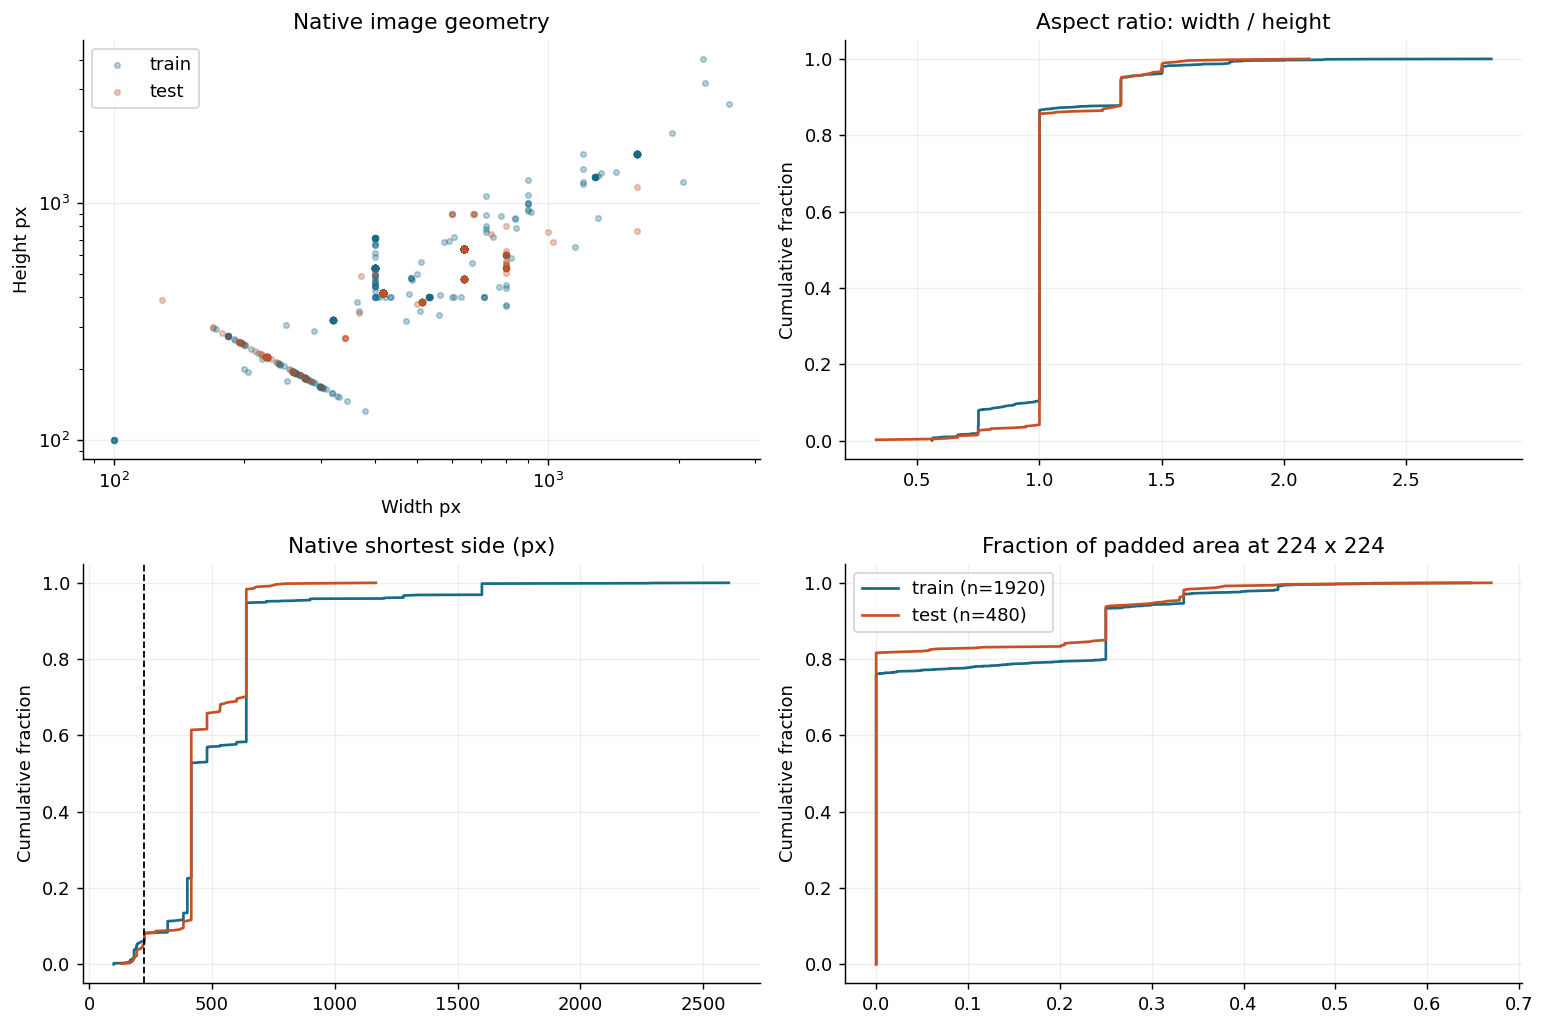

In [14]:
display(DisplayImage(filename=str(ctx['report']/'figures/01_geometry.png')))

### Quality Indicators

Kurva menunjukkan sebaran penuh, bukan hanya mean. Ketajaman dan entropy dipengaruhi tekstur asli; jangan menyebut semua nilai rendah sebagai data rusak.

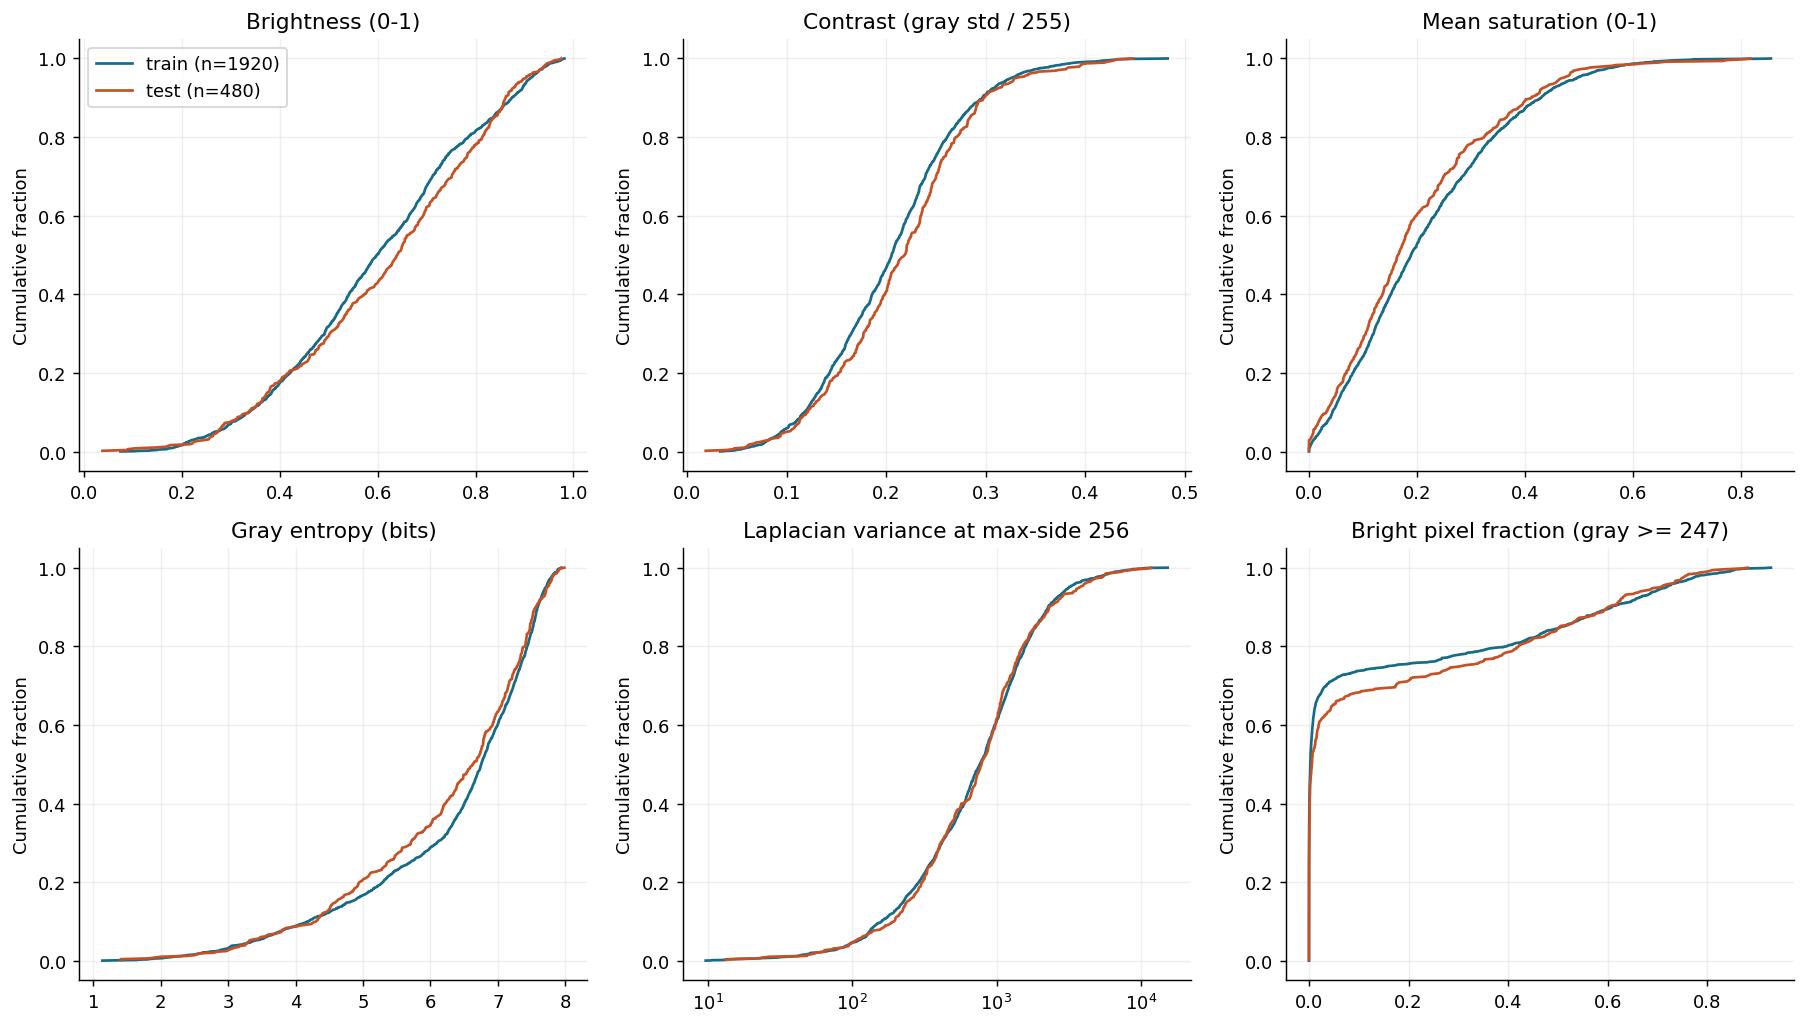

In [15]:
display(DisplayImage(filename=str(ctx['report']/'figures/02_quality_indicators.png')))

### Distribution Shift

Urutkan prioritas dari besarnya perbedaan fitur dan contoh aktual. Statistik saja belum menjelaskan penyebab atau membuktikan solusi augmentasi tertentu.

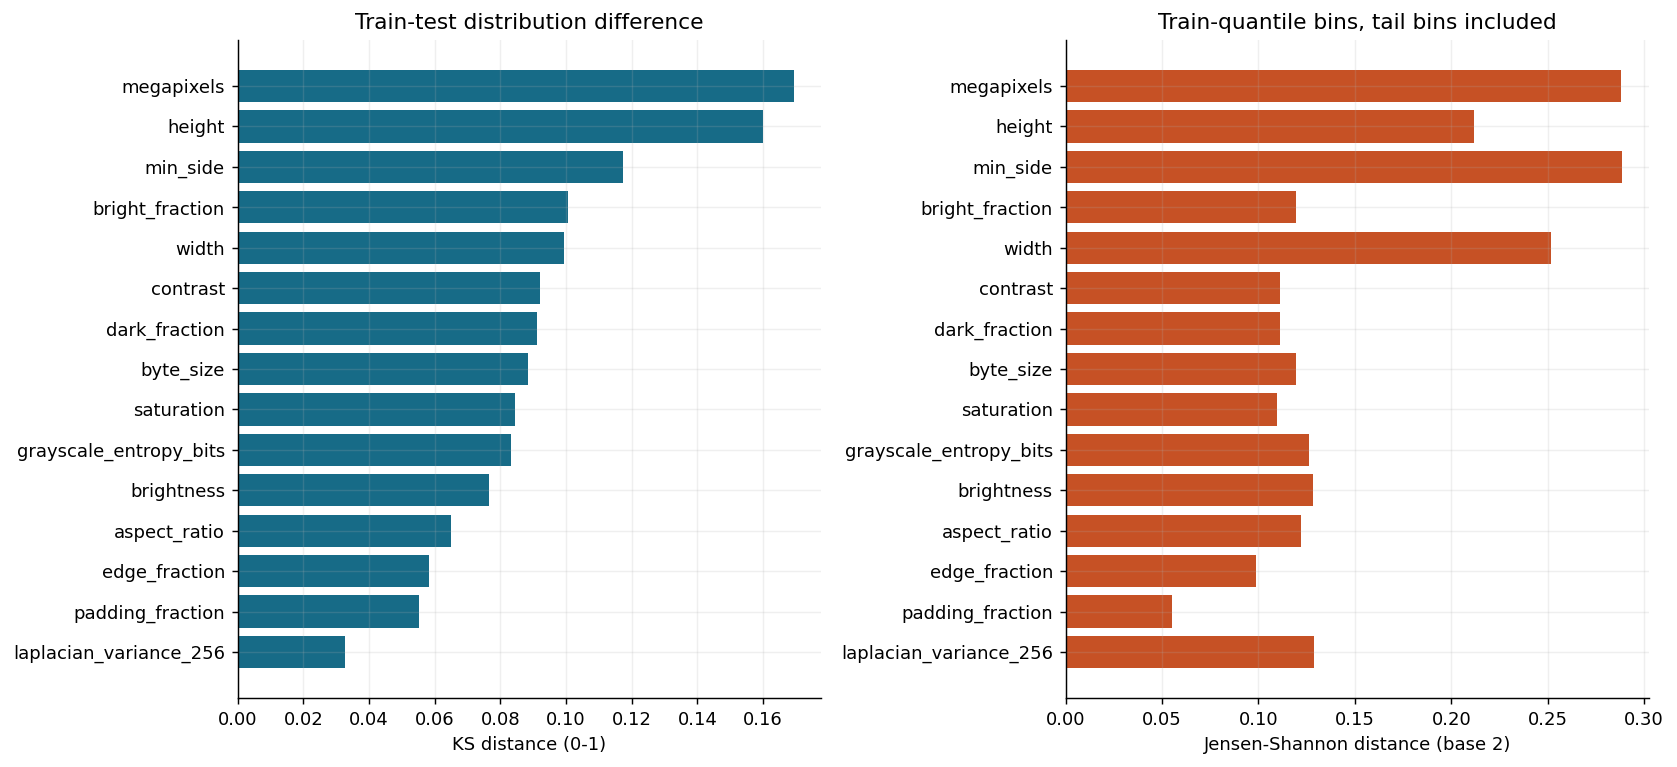

In [16]:
display(DisplayImage(filename=str(ctx['report']/'figures/03_distribution_shift.png')))

### Format And Slices

Format, warna, dan geometri dapat menjadi petunjuk sumber data. Standarisasi RGB membantu input konsisten tanpa memaksakan grayscale.

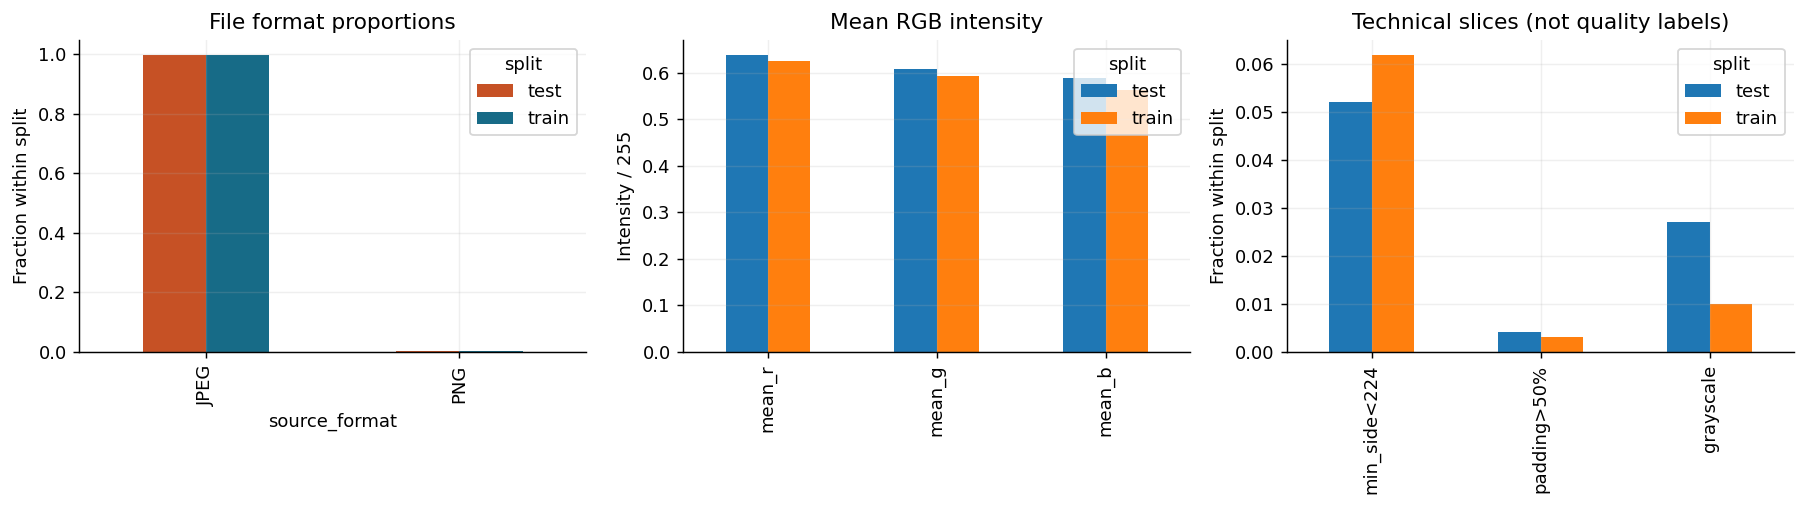

In [17]:
display(DisplayImage(filename=str(ctx['report']/'figures/04_format_and_slices.png')))

### Similarity

Kenaikan jumlah pasangan pada ambang longgar menunjukkan sensitivitas threshold. Kandidat perlu ditelaah dan tidak menjadi jalur penyalinan label.

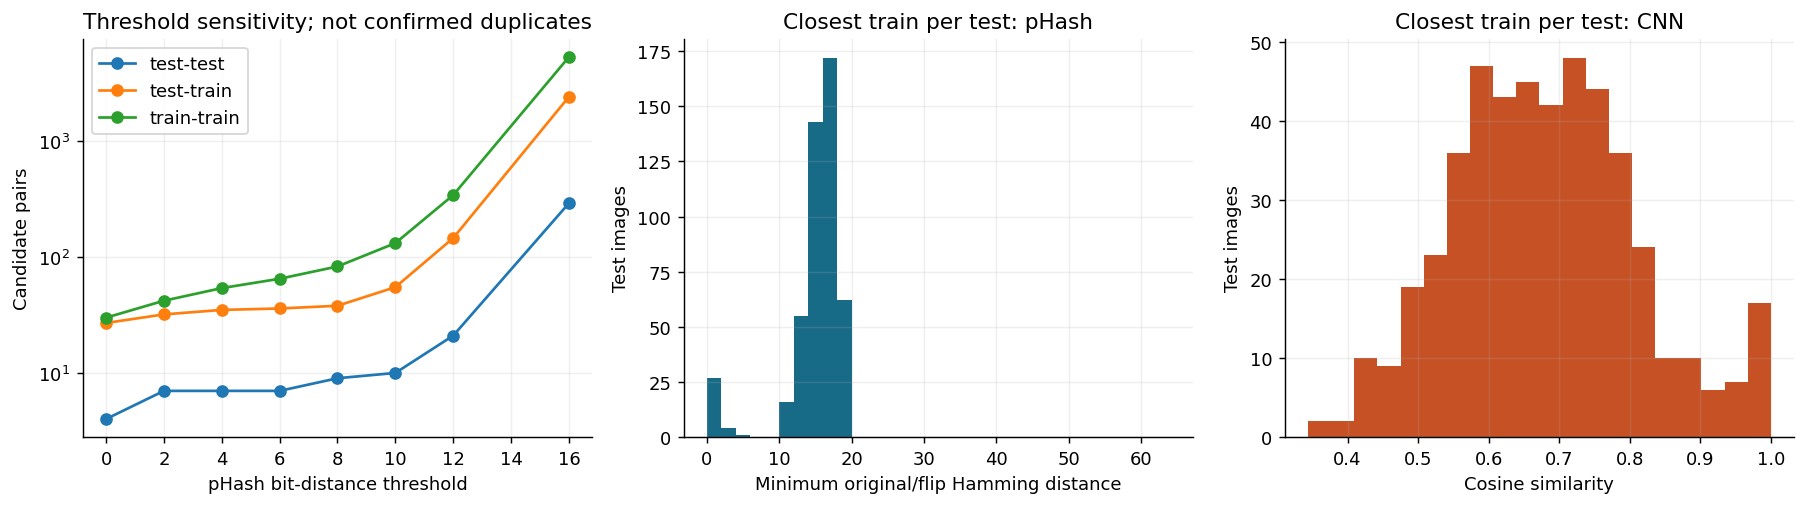

In [18]:
display(DisplayImage(filename=str(ctx['report']/'figures/05_similarity.png')))

### Cluster Navigation

PCA dua dimensi hanya navigasi. Cluster dihitung dalam representasi berdimensi lebih tinggi, bukan dari plot ini.

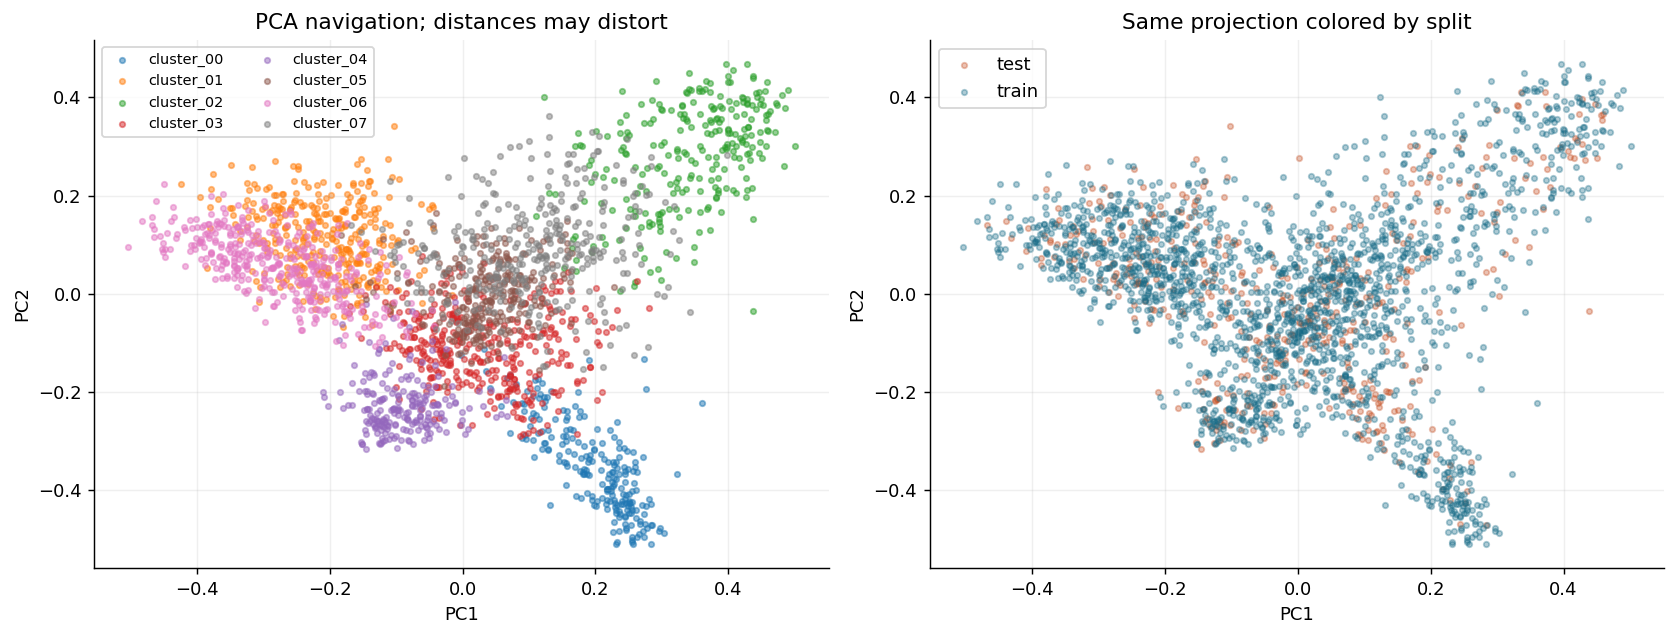

In [19]:
display(DisplayImage(filename=str(ctx['report']/'figures/06_cluster_navigation.png')))

### Cluster Populations

Ukuran kelompok tidak sama dengan jumlah kelas yang benar. Perbedaan komposisi train-test memberi pertanyaan cakupan, bukan prior label yang dipaksakan.

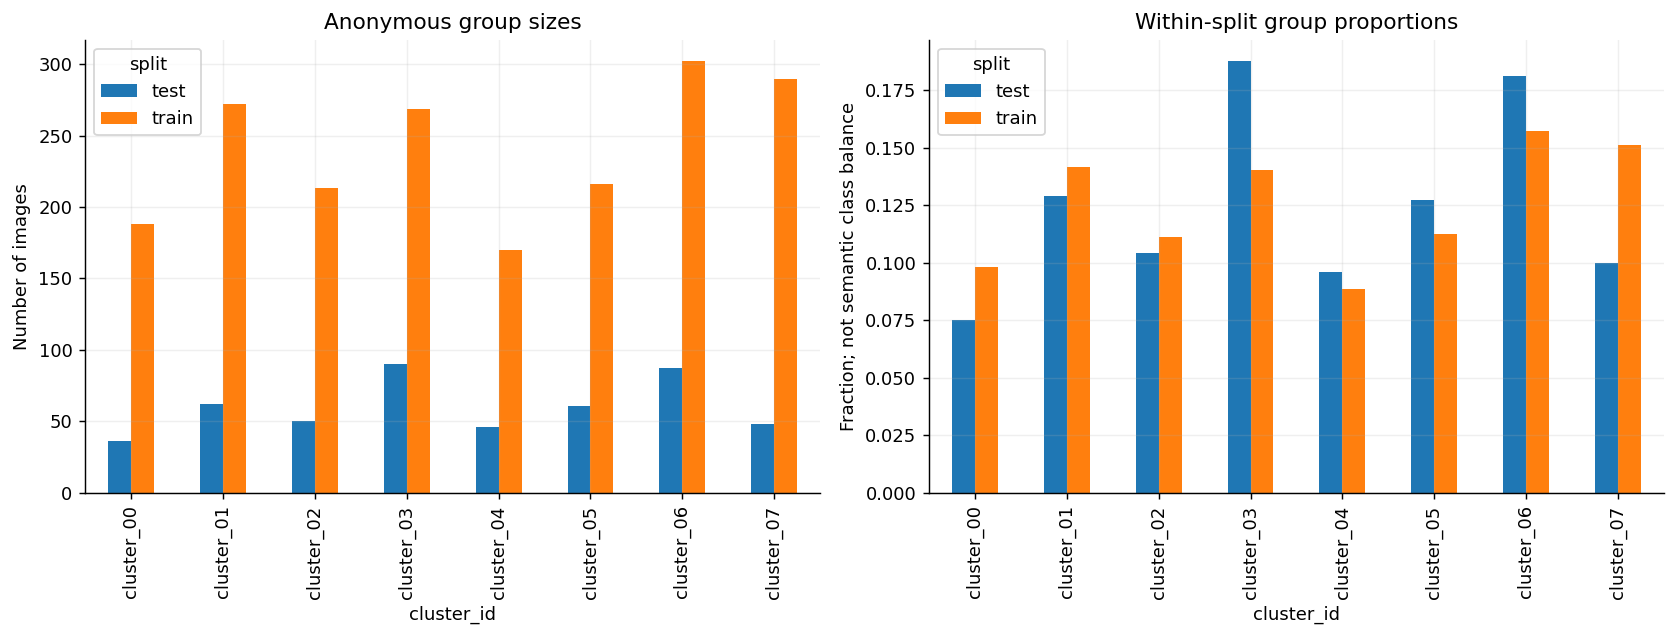

In [20]:
display(DisplayImage(filename=str(ctx['report']/'figures/07_cluster_populations.png')))

### Cluster Diagnostics

Stabilitas tinggi berarti metode konsisten terhadap seed, bukan kategori pasti benar. Nilai internal berbeda ruang fitur tidak bisa dijadikan perlombaan Accuracy.

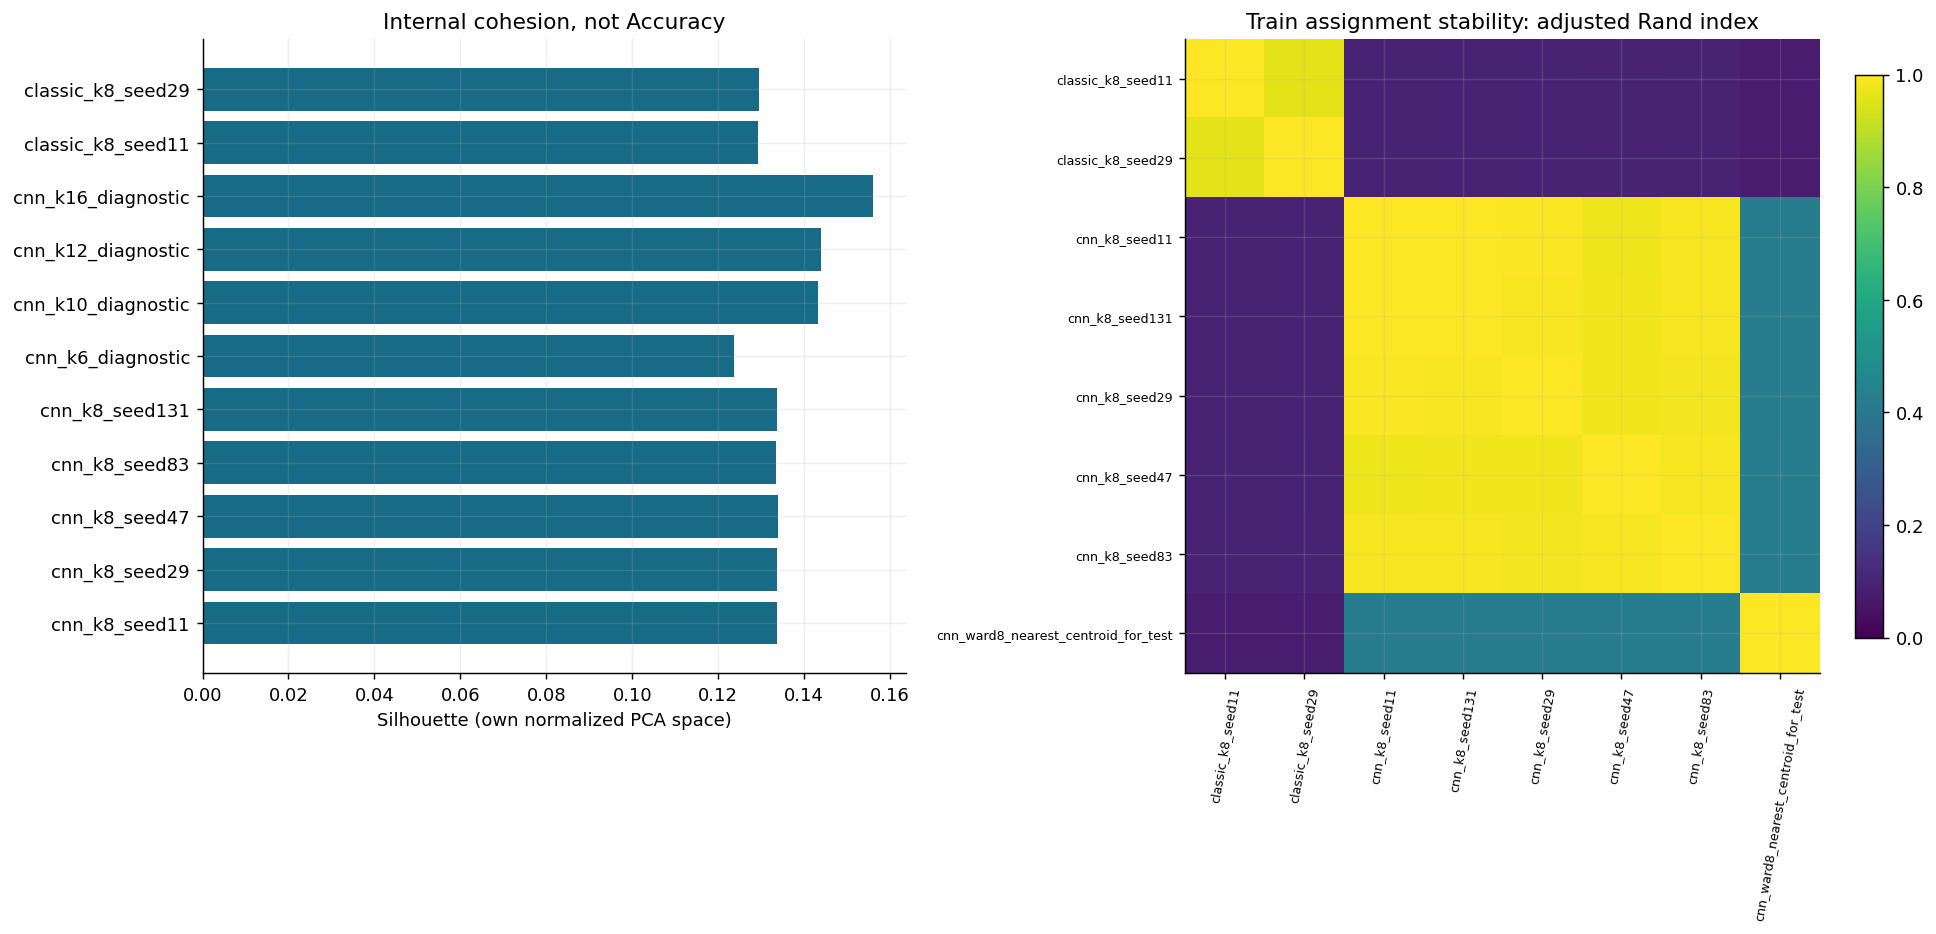

In [21]:
display(DisplayImage(filename=str(ctx['report']/'figures/08_cluster_diagnostics.png')))

### Validation And Stability

AUC domain mengukur keterbedaan train-test; agreement seed mengukur ketidakstabilan cluster. Keduanya bukan confidence klasifikasi material.

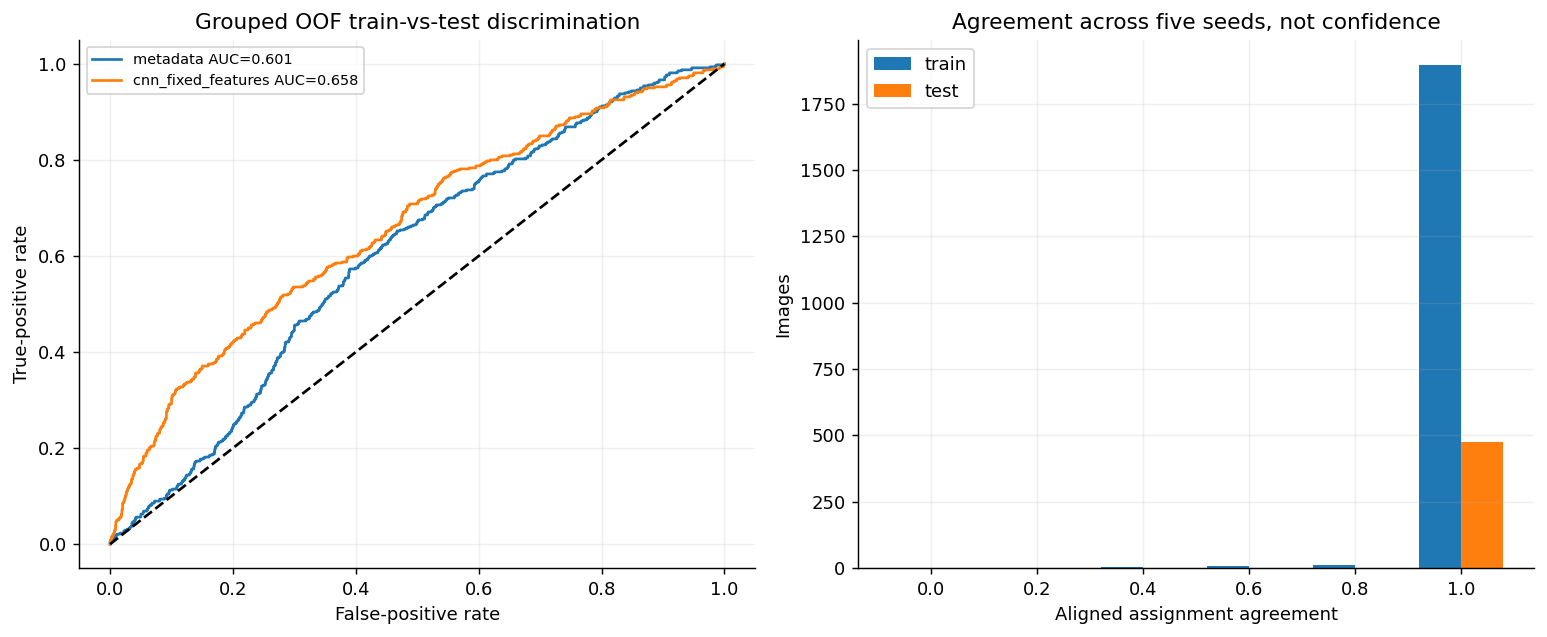

In [22]:
display(DisplayImage(filename=str(ctx['report']/'figures/09_validation_and_stability.png')))

### Preprocessing Comparison

Letterbox mempertahankan frame penuh. Stretch mengubah bentuk; crop memotong area. Dampak ke Accuracy baru dapat diuji pada tahap model berikutnya.

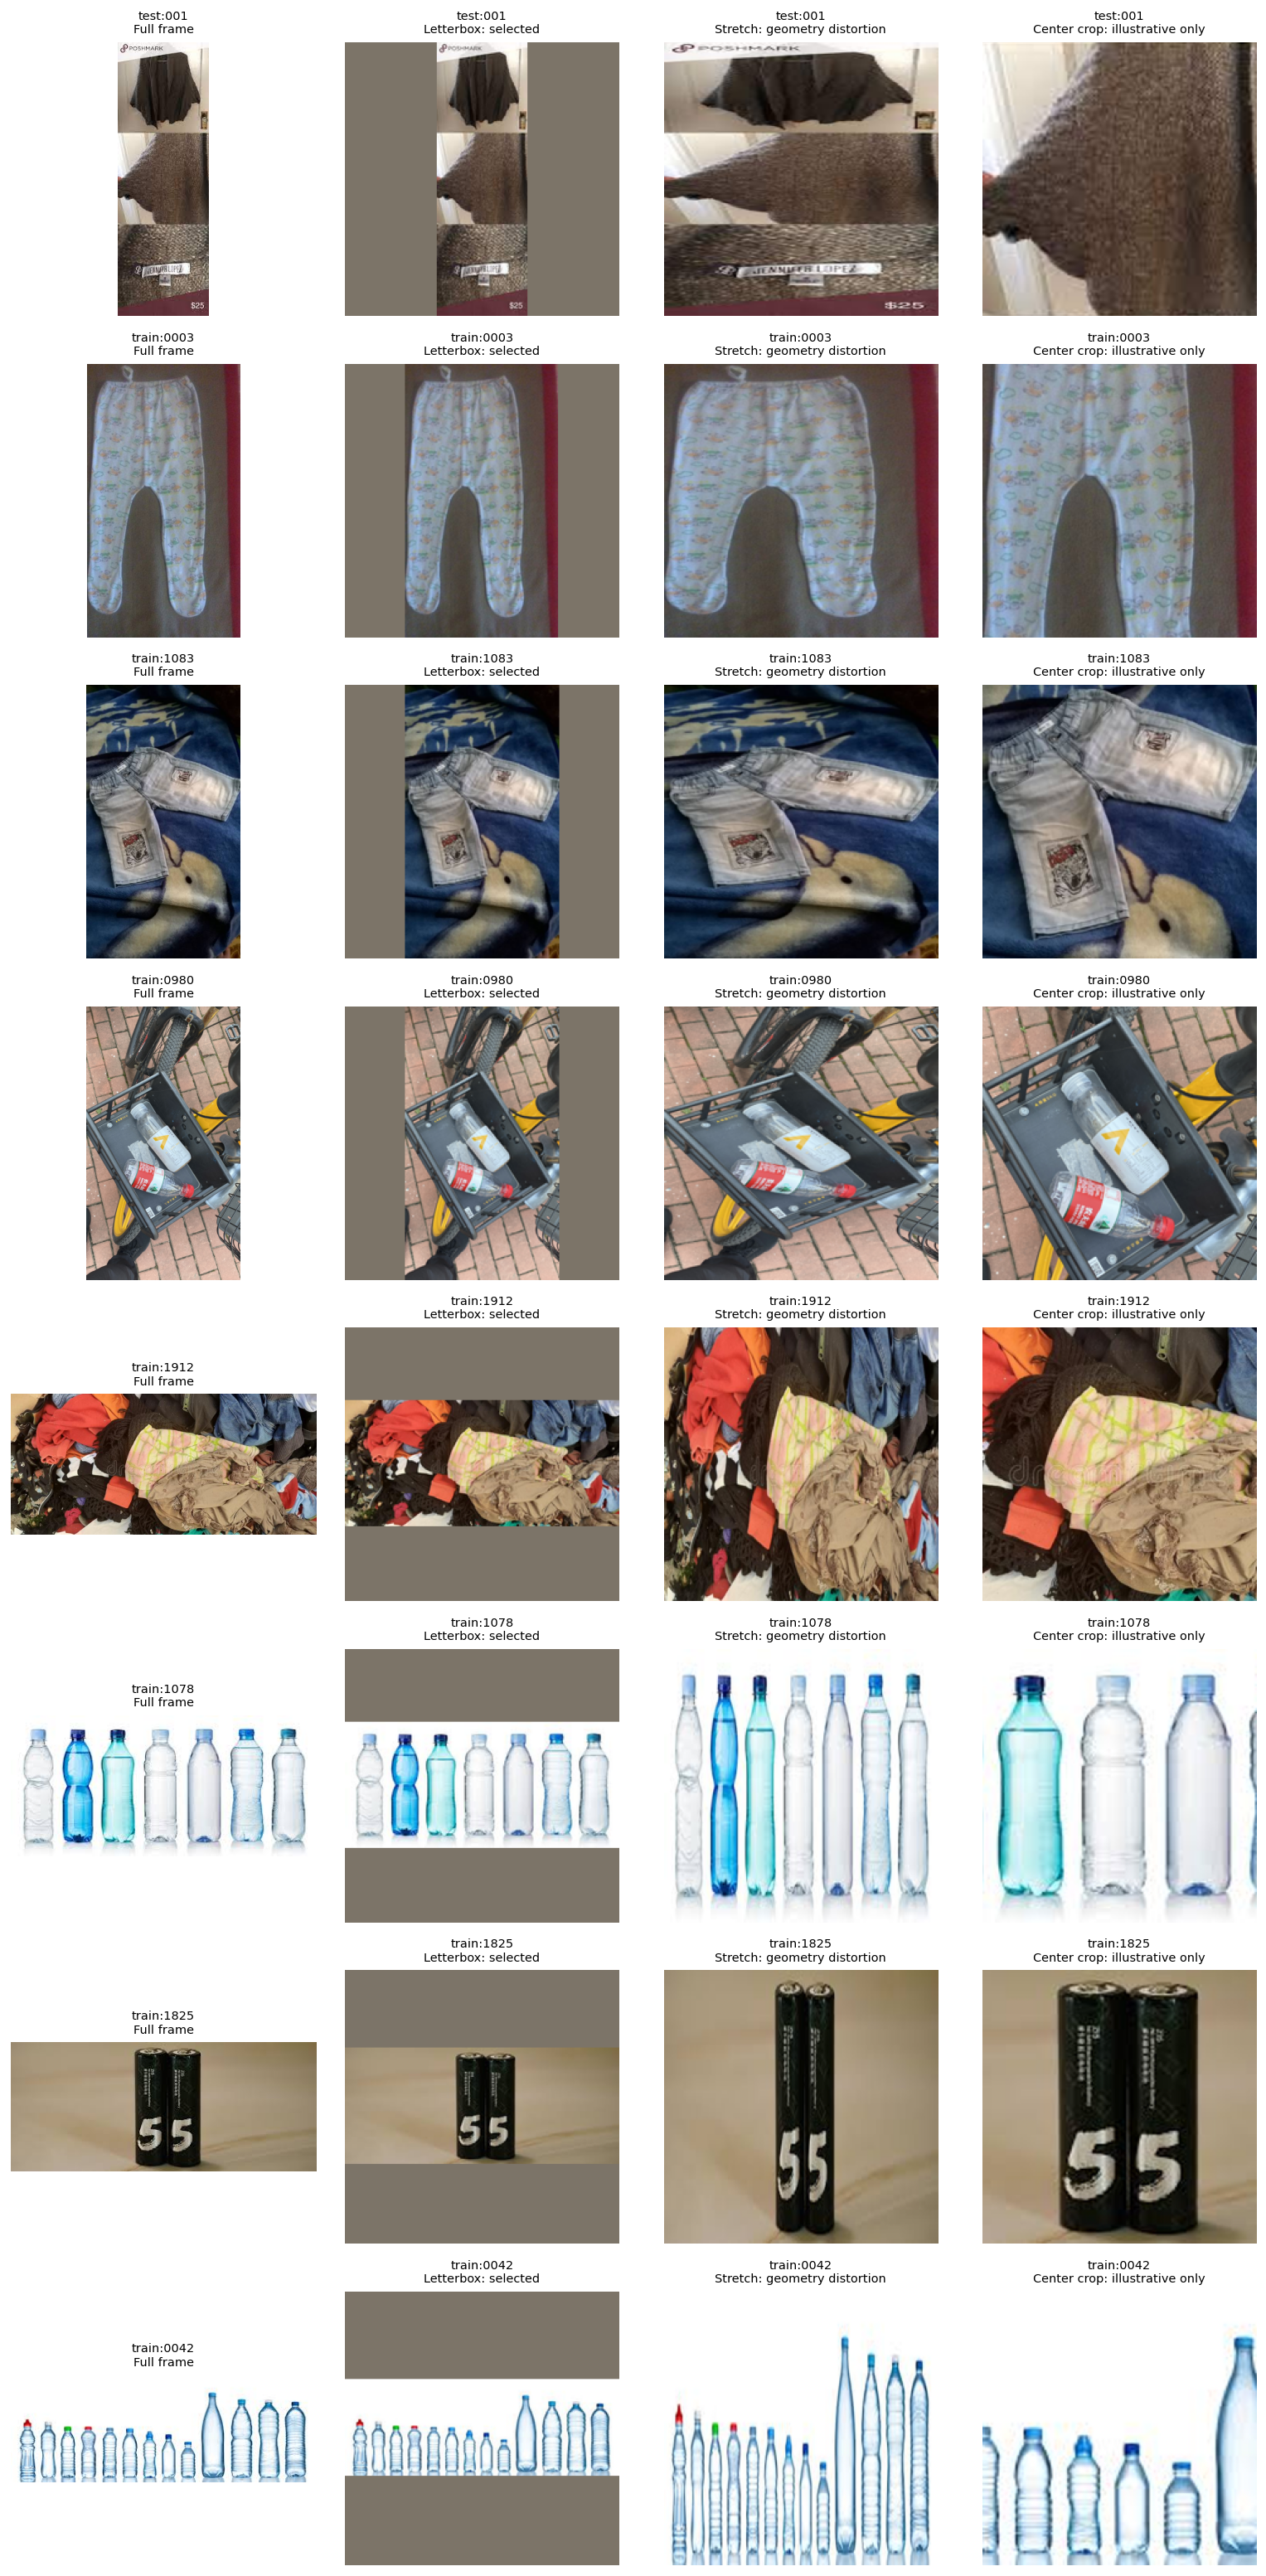

In [23]:
display(DisplayImage(filename=str(ctx['report']/'figures/10_preprocessing_comparison.png')))

## 11. Analisis hasil aktual dan keputusan

Ringkasan berikut dibuat dari tabel run, sehingga angka, rujukan, keterbatasan, dan keputusan preprocessing konsisten dengan keluaran yang sedang diperiksa.

In [24]:
analysis_text = write_analysis(ctx, profile, clusters)
display(Markdown(analysis_text))

# Tahap 1 — EDA, preprocessing, kemiripan dan clustering

Status: pipeline dijalankan pada seluruh sumber. Ini analisis tanpa target kategori resmi, bukan evaluasi Accuracy classifier.

## 1. Pertanyaan dan cakupan

Apakah data lengkap dan dapat dibaca? Bagaimana train berbeda dari test? Apakah ada citra identik atau hampir sama? Seberapa stabil kelompok yang muncul tanpa label? Transform apa yang dapat dipertanggungjawabkan?

Train 1,920; test 480; gagal decode 0. ID test mengikuti sample. Kolom kategori contoh tidak digunakan. Direktori tambahan di bawah train tidak dihitung sebagai sampel.

## 2. Integritas dan representasi

2,400 citra telah didekode, dibuat RGB PNG native, dan diperiksa kesamaan piksel hasil simpan/baca. SHA-256 sumber diperiksa sebelum dan sesudah. EXIF diterapkan satu kali; alpha dikomposit putih. Tidak ada penghapusan citra atau koreksi kategori.

ICC dicatat sebagai metadata; belum dilakukan konversi profil warna ICC. Gamma/warna JPEG mengikuti decoder Pillow. Frame tambahan GIF/TIFF dicatat; pipeline ini memakai frame pertama. Lihat metadata sebelum memutuskan penanganan khusus.

## 3. Geometri, kualitas, dan preprocessing

- test: median ukuran 416×416; min-side<224 25/480; padding median 0.0%; grayscale efektif 13/480.
- train: median ukuran 509×486; min-side<224 119/1920; padding median 0.0%; grayscale efektif 19/1920.

Native RGB dipertahankan agar resolusi model berikutnya masih dapat dipilih. Letterbox 224 hanya representasi eksplorasi backbone: seluruh frame dipertahankan, dengan padding warna rerata ImageNet. Resize meregangkan geometri, sedangkan center crop dapat menghilangkan tepi; keduanya hanya pembanding visual, bukan perubahan data aktif.

Blur, entropy, exposure, dan edge density adalah indikator: citra polos memang dapat memiliki entropy/ketajaman rendah. Ekor distribusi tidak otomatis berarti gambar rusak. Ambang persentil dipelajari dari train untuk antrean tinjauan, bukan seleksi/hapus data.

## 4. Pergeseran train–test

- megapixels: KS=0.1693, JS distance=0.2882, median train/test=0.2136/0.1731, BH-q=7e-09.
- height: KS=0.1599, JS distance=0.2116, median train/test=485.5/416, BH-q=3.85e-08.
- min_side: KS=0.1172, JS distance=0.2882, median train/test=416/416, BH-q=0.000246.
- bright_fraction: KS=0.1005, JS distance=0.1194, median train/test=0.002563/0.005814, BH-q=0.00286.
- width: KS=0.0995, JS distance=0.2514, median train/test=509/416, BH-q=0.00286.

KS di sini jarak distribusi fitur, bukan metrik target kompetisi. P-value dikoreksi BH untuk banyak pengujian; pengulangan/kemiripan gambar tetap dapat melanggar asumsi independen. Effect size dan grafik lebih informatif daripada label signifikan saja. Bin JS memakai kuantil train dengan tail bins agar nilai test di luar rentang tidak hilang.

- Domain classifier metadata: grouped OOF AUC=0.6006. Target hanya asal split train/test; bukan kategori limbah atau Accuracy kompetisi.
- Domain classifier cnn_fixed_features: grouped OOF AUC=0.6578. Target hanya asal split train/test; bukan kategori limbah atau Accuracy kompetisi.

StandardScaler dan regresi logistik domain fit di tiap train fold. Grup kandidat pHash tidak menyeberang fold. CNN sebagai fitur tetap tidak dilatih dengan domain target. Hasil ini mendeteksi keterbedaan, tidak menunjukkan penyebab kausal atau otomatis membenarkan reweighting.

## 5. Duplikasi dan kemiripan

Pasangan byte-identik: 4; pixel-identik setelah canonical RGB: 4. Kandidat pHash≤6: 108. Grup kandidat dengan risiko rantai/diameter>4: 0. Tidak semua kandidat adalah foto/objek yang sama.

Dari 480 test, 3 memiliki train dengan pixel identik; 32 memiliki kandidat pHash≤6. Tidak ada penyalinan label maupun penggantian prediksi berdasarkan tetangga.

CNN nearest-train cosine median=0.6744. pHash menangkap struktur visual kasar; CNN dapat dekat karena bentuk, material, objek, maupun latar. Jarak/cosine bukan probabilitas benar. Seluruh 480 test tersedia dalam galeri tetangga.

## 6. Clustering dan stabilitas

Primary telah ditetapkan sebelum perbandingan arsip: ResNet50 ImageNet1K V2, full-frame letterbox, L2 features, PCA64 fit pada train unik, renormalisasi, KMeans k=8 seed11 n_init10. Hanya satu wakil pixel-identik masuk fitting PCA/cluster. Test diproyeksikan dan diassign ke centroid train tanpa fit ulang.

Pembanding: lima seed CNN, dua seed fitur HSV+HOG, Ward8, serta k=6/10/12/16 sebagai sensitivitas eksplorasi. Ini belum pemilihan kategori atau izin memperlakukan subcluster sebagai label akhir. Silhouette antar representasi tidak otomatis sebanding dan tidak menentukan kebenaran semantik.

Primary silhouette=0.1336; ukuran cluster train unik 169–302. ARI antar seed CNN: minimum 0.9755, median 0.9850.

Antrean tinjauan algoritmis: 612 gambar. Alasan: margin centroid<0,10, agreement seed<0,80, atau jarak di atas p95 cluster train. Ini indikator ketidakstabilan, bukan bukti salah label; tidak ada perbaikan per gambar otomatis/manual.

Folder cluster_00…cluster_07 berisi gambar hasil preprocessing. Nama glass/paper/dan seterusnya belum dipetakan; anggota tim perlu menamai cluster dengan dasar yang dicatat. Satu cluster tidak dijamin sama dengan satu kelas; pemetaan kosong lebih jujur daripada memaksakan delapan kategori.

## 7. Validasi yang dapat dan belum dapat disimpulkan

Draft 5-fold memakai group kandidat dan stratifikasi cluster anonim. Tidak ada grup kandidat menyeberang fold. Karena clustering fit pada seluruh train, agreement classifier terhadap target cluster global bukan validasi semantik independen. Pada tahap berikutnya, learned preprocessing/target construction perlu dibatasi ke train fold jika mengklaim out-of-sample; test Kaggle tetap tersembunyi.

Belum ada Accuracy kategori, confusion matrix kategori, atau classifier limbah yang dilatih/fine-tune. Backbone frozen hanya untuk eksplorasi. Jalur final pretrained memerlukan pelatihan/fine-tuning kompetisi sesuai aturan. Public sempurna pun tidak memastikan private sempurna.

## 8. Pelajaran INFEST dan webinar

Penilaian INFEST menekankan keterkaitan temuan data→preprocessing→evaluasi, visualisasi bernarasi, serta notebook yang benar-benar dieksekusi. Temuan tersebut diadopsi; aturan dan Macro-F1 INFEST tidak dipindahkan ke GELAR RASA. Laporan penelaahan Excel terpisah memuat sumber sheet/sel.

Materi 1 h.11–14: representasi RGB, split, augmentasi dan baseline; h.17–18 fitur hybrid; h.20 transform hati-hati; h.22–29 evaluasi/learning curves. Materi 2 h.12–19 dan 33–34: grafik, denominator, konsistensi, integritas. Tidak mengasumsikan bahwa perbaikan visual otomatis memperbaiki klasifikasi.

## 9. Keputusan dan langkah berikutnya

1. Gunakan manifest sumber, bukan recursive glob seluruh train.
2. Pertahankan native RGB serta koordinat/rasio letterbox; jangan denoise/CLAHE/crop massal tanpa ablasi.
3. Tinjau grup near-duplicate dan risiko rantainya sebelum menjadikan group_id sebagai split final.
4. Tim memetakan nama kategori cluster dan mencatat bila kelompok tidak koheren; jangan memaksakan koreksi satu per satu.
5. Bekukan versi label dan split yang sah, lalu lakukan fine-tuning serta evaluasi tahap berikutnya. Jangan memakai skor internal clustering sebagai estimasi leaderboard.

## Artefak dan reproduksi

- `output/manifests/stage1_v1/`: sumber, metadata, SHA-256.
- `data/processed/stage1_v1/`: native RGB, letterbox, folder cluster train/test, template mapping.
- `output/groups/stage1_v1/`: exact groups, kandidat, cluster assignment dan provenance.
- `reports/eda/stage1_20261105/galleries/index.html`: semua gambar dan tetangga.
- `notebook/01_EDA_Preprocessing_Clustering.ipynb`: kode mandiri dan hasil eksekusi.

Keluaran processed diperlakukan immutable; cluster_views memakai hardlink bila filesystem mendukung, jadi mengedit file di satu view juga mengubah salinan native yang terkait. Untuk perubahan baru gunakan versi output baru.

Tanggal/asumsi aturan: 5 November 2026. Bantuan penulisan kode berdasarkan klarifikasi pengguna diperbolehkan selama notebook tidak memanggil LLM; notebook ini tidak memakai layanan inference eksternal atau VLM.


## 12. Pemeriksaan akhir

Sel akhir memeriksa ulang byte sumber, cakupan ID, grup exact, dan status kategori. Berhasil menjalankan tahap 1 berarti integritas dan artefak analisis tersedia; bukan sertifikasi label atau jaminan leaderboard. Native RGB dan cluster views diperlakukan immutable; sebagian views merupakan hardlink.

In [25]:
summary = finalize(ctx, profile, clusters, groups)
display(summary)
print('STAGE 1 COMPLETE — EDA and unsupervised groups, semantic mapping pending.')

2026-11-05 06:38:58 Stage 1 integrity checks passed; semantic mapping remains for the team.


{'total': 2400,
 'train': 1920,
 'test': 480,
 'decode_errors': 0,
 'raw_hashes_rechecked': 2400,
 'rgb_roundtrip_verified': 2400,
 'pixel_unique_train': 1919,
 'semantic_labels_ready': False,
 'classifier_trained': False,
 'category_accuracy_measured': False,
 'cluster_review_count': 612,
 'train_review_count': 498,
 'test_review_count': 114,
 'claim': 'Executed EDA and unsupervised clustering; no semantic ground truth evaluation'}

STAGE 1 COMPLETE — EDA and unsupervised groups, semantic mapping pending.
